# Set-up

## Library

In [1]:
# Install and import libraries
%pip install geopandas matplotlib seaborn pyreadr pandas numpy rapidfuzz tqdm spopt shapely pyarrow numba binsreg scipy pyfixest

# Data reading and modification
import geopandas as gpd 
from geopandas import sjoin_nearest
import pandas as pd
import numpy as np
import pandas as pd
import pyreadr as pyr # Read R file

# Plots
import matplotlib as mpl
import matplotlib.pyplot as plt 
import seaborn as sns
from plotnine import *

# Non-Parametric method
from binsreg import *
import scipy
from pyfixest import feols

# Other uses
from scipy.sparse import block_diag
from rapidfuzz import process, fuzz
from tqdm import tqdm
import re
import numba
import warnings
warnings.filterwarnings('ignore')
from pprint import pprint
    

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


## Files

In [2]:
# Read R data
try:
    rais_original = pd.read_parquet(r'Dados/Rais/rais_niteroi_2009_2023_Original.parquet')
    print("rais_original loaded.")
except Exception as e:
    print(f'Error - rais-original: {e}')
    t = pyr.read_r(r'Dados/Rais/rais_niteroi_2009_2023.rds')
    rais_original = t[None]
    rais_original.to_parquet(r'Dados/Rais/rais_niteroi_2009_2023_Original.parquet')

# Read CSV and shapefiles
try:
    rais = pd.read_parquet(r'Tratamento de Dados/rais.parquet', engine='pyarrow')
    print("rais loaded.")
except Exception as e:
    print(f'Error - rais: {e}')
    rais = rais_original.copy()

# Read geometry
try:
    geometry = gpd.read_parquet(r'Tratamento de Dados/lotes.parquet')
    print('geometry loaded')
except Exception as e:
    print(f'Error - geometry: {e}')

# Read census data
try:
    census = gpd.read_parquet(r'Dados/Demografia/census.parquet')
    print("census loaded")
except Exception as e:
    print(f'Error - census: {e}')


rais_original loaded.
rais loaded.
geometry loaded
census loaded


## Define Functions

### Street Matching

In [3]:
def match_streets(rais = rais, geometry = geometry, 
                  ad: str ='endereco',
                  street: str =None,
                  hn: str = None,
                  street_col: str ='endereco',
                  threshold: int = 20):
    
    # Rename columns
    rename_map = {}
    if street:
        rename_map[street] = 'STREET_MATCHED'
    if hn:
        rename_map[hn] = 'HOUSE_NUMBER'
    if rename_map:
        geometry = geometry.rename(columns=rename_map)

    # Create new column with street names
    if 'HOUSE_NUMBER' in geometry.columns:
        geometry[ad] = geometry['STREET_MATCHED'].fillna('') + ' ' + geometry['HOUSE_NUMBER'].fillna('')
    else:
        geometry[ad] = geometry['STREET_MATCHED']
    
    geometry[ad] = geometry[ad].str.strip()

    # Candidates
    candidates_street = geometry['STREET_MATCHED'].dropna().str.upper().unique().tolist()

    # Create a dictonary with street name and it's matched conterpart
    geometry_upper = geometry['STREET_MATCHED'].str.upper()
    ad_per_st = (
        geometry.assign(_STREET_UPPER=geometry_upper)
        .dropna(subset=['_STREET_UPPER'])
        .groupby('_STREET_UPPER')[ad]
        .apply(lambda s: s.dropna().str.upper().tolist())
        .to_dict()
    )

    def find_best_match(street_name_str):
        if street_name_str in ('', 'NAN', 'NONE'):
            return None
        if not candidates_street:
            return None

        # Match by name
        result = process.extractOne(
            street_name_str,
            candidates_street,
            scorer=fuzz.WRatio
        )

        if not result or result[1] < threshold:
            return None

        st_matched = result[0]
        candidates_filtred = ad_per_st.get(st_matched, [])

        if not candidates_filtred:
            return st_matched

        result_full = process.extractOne(
            street_name_str,
            candidates_filtred,
            scorer=fuzz.WRatio
        )

        if result_full and result_full[1] >= threshold:
            return result_full[0]
        return st_matched

    # Unique values for computational economy
    street_upper_series = rais[street_col].astype(str).str.strip().str.upper()
    unique_streets = street_upper_series[rais[street_col].notna()].unique()

    mapping = {
        s: find_best_match(s)
        for s in tqdm(unique_streets, desc="Cruzando Ruas (únicos)")
    }
    
    rais['STREET_MATCHED'] = street_upper_series.map(mapping)
    rais.loc[rais[street_col].isna(), 'STREET_MATCHED'] = None

    matched = rais['STREET_MATCHED'].notna().sum()
    total = len(rais)
    print(f"{matched} de {total} linhas encontraram par ({matched/total*100:.1f}%)")

    return rais, geometry


### Bikes

In [4]:
def bike(base, name: str):

    print('-' * 100,
           sep = '\n')
     
    base = base.set_geometry('geometry')
        
    # Filter Bike lanes
    try:      
        bikes = gpd.read_file(r'Dados/Infraestrutura/Infraestrutura_Cicloviária.shp')
        bikes = bikes.set_geometry('geometry')
        print('bikes loaded')
    except Exception as e:
        raise ValueError(f'Error - loading bikes: {e}')

    if bikes.crs == None:
        raise ValueError('bikes crs null')
    if base.crs == None:
        raise ValueError('base crs null')

    if bikes.crs != base.crs:
        base = base.to_crs(31983)
        bikes = bikes.to_crs(31983)
        print('bikes and base crs changed')

    try:
        # Adjust date format
        bikes['dt_inaugur'] = pd.to_datetime(bikes['dt_inaugur']).dt.year.astype('Int64')
        print('date format changed',
              f'period is: {bikes['dt_inaugur'].unique()}',
              sep = '\n')
    except Exception as e:
        raise ValueError(f'Error - first date convertion: {e}') 

    try:
        bikes.loc[(bikes['dt_inaugur'] < 2009), 'dt_inaugur'] = 2050
        print('group changed - 2050')
    except Exception as e:
        raise ValueError(f'Error - group - 2050: {e}') 

    try:
        bikes.loc[(bikes["dt_inaugur"].isnull()), 'dt_inaugur'] = 2050
        print('group changed - null')
    except Exception as e:
        raise ValueError(f'Error - group - null: {e}') 

    print('unique dates:',
          bikes['dt_inaugur'].unique(),
          sep = '\n')

    try:
        base = sjoin_nearest(base, bikes[['geometry', 'dt_inaugur', 'tx_tipo']], how='left', distance_col='dist')
        print('sjoin completed')    
    except:
        try:
            base = base.drop(columns='index_right')
            base = sjoin_nearest(base, bikes[['geometry', 'dt_inaugur', 'tx_tipo']], how='left', distance_col='dist')
            print('Exception called: sjoin completed')
        except Exception as e:
            raise ValueError(f'Error - sjoin: {e}')

    save(base, name)

    print('-' * 100,
          sep = '\n')

    return base


### Treatment

In [5]:
def dista(base, dist: float = 100, id: str = 'id', og: bool = True, b_year: int = 2012, c_year: int = 2022,
          e_year: int = 2022):
      '''
      dist = max distance to define treatment
      id = id column
      og = boolean to change between original function or new 
      b_year
      c_year = chosen group for control
      e_year = year to end the df
      '''

      print('-' * 100,
            'initializing treatment selection...',
            f'distance set to: {dist} meters',
            sep = '\n')

      ids = ['13217', '9395', '9237', '10358', '10518', '10198', '11797', '11639', '11799', '12600', '12440',
             '7934', '8095', '8255', '9720', '8415', '8575', '8736', '8896', '9057', '9056', '9216', '9377',
             '9537', '9698', '9858', '9857', '10018', '10178', '10339', '10498', '10499', '10659', '10819',
             '10979', '10980', '11139', '8254', '9234', '11796', '12598']

      a = base.copy()
      a = a[(a['year'] <= e_year) & (a['year'] >= b_year)]
      
      yrs = a['year'].unique()
      yrs = np.insert(yrs, 0, 0)

      a['treatment'] = 0

      if "group" in a.columns: 
            try:
                  a = a.drop(columns = ['group', 'index_right', 'tx_tipo_right'])
                  print('old columns dropped')

                  try:
                        a = a.rename(columns = {'dt_inaugur': 'group'})
                        print('dt_inaugur renamed to group')
                  except Exception as e:
                        raise ValueError(f'Error - dt_inaugur renaming: {e}')
            except:
                  pass
      else:
            try:
                  a = a.rename(columns = {'dt_inaugur': 'group'})
                  print('dt_inaugur renamed to group')
            except Exception as e:
                  raise ValueError(f'Error - dt_inaugur renaming: {e}')
            
      a = a[a['group'].isin(yrs)]

      a['group'] = a.groupby(a[id])['group'].transform('min')
      a['min_dist'] = a.groupby(id)['dist'].transform('min')
      a['treatment'] = (a['min_dist'] <= dist).astype(int)
      a['group'] = a['group'].fillna(0)
      
      mask_control = a['treatment'] == 0
      a.loc[mask_control, 'group'] = 0
      a.loc[mask_control, 'tx_tipo'] = 'NaN'

      if og == False:
            pre = len(a)
            a = a[(a['group'] != 0) & (~a['id'].isin(ids))]
            post = len(a)

            print('-' * 100,
                  f'{pre - post} units dropped for new version',
                  sep = '\n')

            mask_control = a['group'] == c_year
            a.loc[mask_control, 'treatment'] = 0
            a.loc[mask_control, 'tx_tipo'] = 'NaN'
                  
      a = a.drop(columns=['min_dist'])

      print('-' * 100,
            'result sample:',
            a.head(5),
            'columns:',
            a.keys(),
            '-' * 100,
            sep = '\n')

      print('selection completed!')

      print('-' * 100,
            sep = '\n')

      return a




### Merge with Hex

In [6]:
def merge(base):

    print('-' * 100,
          '-' * 100,
          sep = '\n')

    if base.crs != hex.crs:
        base = base.to_crs(31983)
        base = base.dropna(subset=['geometry'])
        print('crs adjusted')

    print('merging base and hex...', end ='')

    result = []
    for year in base['year'].unique():
        points = base[base['year'] == year]
        hexy = hex[hex['year'] == year]
        r = gpd.sjoin(points, hexy, how = 'right',
                      predicate = 'intersects')
        result.append(r)

    base = pd.concat(result, ignore_index = True)
    base = base.drop(columns = ['year_left']).rename(columns = {'year_right': 'year', 'estoque': 'y'})

    print('done!')

    '''
    print('-' * 100,
          f'sample of merge:',
          base[base['year'] == 2022]['age'].unique(),
          f'new base keys:',
          base.keys(),
          '-' * 100,
          'merge successful?',
          sep = '\n')

    
    while True:
        answer = input("Y/N:")
        if answer.upper() == 'Y':
            print(f'{answer} selected',
                'Great :D',
                'Moving on:',
                sep = '\n')
            break
        elif answer.upper() == 'N':
            print(f'{answer} selected',
                'stopping process',
                sep = '\n')
            raise ValueError("Sjoin failed")
        else:
            print('please, type only "Y" or "N"')
            
    '''

    print('defining geometry...', end = '')
    base = base.set_geometry('geometry')
    base['area'] = base.geometry.area
    print('done!')

    print('filling age and y...', end = '')
    base.loc[(base['age'] == 0), 'age'] = 0.001
    base['age'] = base['age'].fillna(0)
    base['y'] = base['y'].fillna(0)
    print('done!')

    print('grouping base...', end = '')
    base = base[['id_left', 'id_right', 'year', 'area',
                 'group', 'dist', 'y', 'density_m',
                 'tx_tipo','zone', 'age', 'geometry']].groupby(['year','id_right']).agg({
        'y': 'sum',
        'geometry': 'first',
        'id_left': 'count',
        'zone': 'first',
        'tx_tipo': 'first',
        'density_m': 'first',
        'group': 'min',
        'area': 'first',
        'age': 'mean'
    }).reset_index()
    print('done!')

    base = base.set_geometry('geometry')
    base = base.rename(columns = {'id_left': 'count', 'id_right': 'id'})
    base = base.set_crs(31983)

    base['fdensity'] = base['count']/base['area']

    '''
    print('density defined:',
          base['fdensity'].unique())
    '''

    print(f'Sample has {len(base)} observations',
          f'Of that, { base['y'].isna().sum()} are null',
          sep = '\n')
    
    return base


### Non-Parametric - Test

In [7]:
def nparam(base, year_colunn: str = 'year', dist: str = 'dist', w = None, id: str = 'id', prep = (2010,2011), y: str = 'y', nbins: int = 20, name: str = 'np_dbaa', by = None,
           polyreg: int = 3, test: bool = False, true_dist: bool = False):
      '''
      base => df to be used
      year => year column
      dist => distance column
      id => id column
      prep => last two periods before treatment
      y => dependent variable
      nbins => number of bins
      name => name shown in results
      '''
      
      b = base.copy()
      b['ln_y'] = np.log1p(b[y])

      a = b[(b[year_colunn].isin(prep)) & ((b['group'] >= prep[0]) | (b['group'] == 0))]

      c = a.groupby([year_colunn, id])[y].size().reset_index(name = 'n')
      c = c[c['n'] > 1]
      a = a[~a[id].isin(c[id])]
      
      wide = a.pivot(index = id, columns = year_colunn, values = 'ln_y')
      d = (wide[prep[1]] - wide[prep[0]]).rename('d_ln_y')

      cols = [dist] + list(w or []) + ([by] if by else [])
      fixed = b.groupby(id)[cols].first()

      a = fixed.join(d).dropna(subset = ['d_ln_y'] + cols)

      if true_dist == False:
            a[dist] = np.log1p(a[dist])

      if test == False:
            maxd = binsreg(y = 'd_ln_y', x = dist, w = w,
                              nbins = nbins, ci = (0,0),
                              data = a, randcut = 1,
                              cb = (0,0), nsims = 2000,
                              simsgrid = 50, polyreg = polyreg,
                              by = by)
                  
            maxd.bins_plot
            rmaxd = maxd.data_plot[0]

            print('-' * 100,
                  f'{name} results:',
                  rmaxd.data_bin,
                  sep = '\n') 
      
      if test == True:
            t = binstest(data = a, y = 'd_ln_y', x = dist,
                         deriv = 1, testshape2 = 0,
                         nbins = nbins, nsims = 2000,
                         simsgrid = 50)
            t = t.testshape2
            print(vars(t))

### Histogram

In [8]:
def plotu(base, title = None, y: str = 'y', year: str = 'year', group: str = 'group', treatment: str = 'treatment', name: str = 'test', mean = False):
    fig, ax = plt.subplots(1,2,figsize = (20,10),layout = 'constrained')

    if title != None:
        fig.suptitle(f"{title}", fontsize = 15, fontweight = "bold")
    
    ax[0].set_title('Histogram')
    ax[1].set_title('Job Variation (2009 - 2022)')

    if mean == False:
        a = base[[group, year, y]].groupby([group, year]).sum().reset_index()
    else:
        a = base[[treatment, year, y]].groupby([treatment, year]).mean().reset_index()
    
    yrs = sorted(a[year].unique())
    ax[1].set_xticks(yrs)
    ax[1].grid(axis='x', linestyle='--', alpha=0.5)
    
    base['treatment'].value_counts().sort_index().plot(kind='bar', ax = ax[0])

    sns.lineplot(data = a,
                ax = ax[1],
                x = year,
                y = y,
                hue = treatment,
                palette='Set2')

    plt.savefig(fr'Resultados/Imagens/group_variation_{name}.png')
    plt.show()



### T-Map Plot

In [9]:
def tplot(base):
    years = ['2009', '2016','2021', '2023']

    fig, axes = plt.subplots(1,len(years), figsize = (15,10),
                        layout = 'constrained')
    
    print('loading bikes df')

    if bikes is None:
        try:
            bikes = gpd.read_file(r'Dados/Infraestrutura/Infraestrutura_Cicloviária.shp') 
            print('bikes loaded')
        except Exception as e:
            raise ValueError(f'Error - loading bikes: {e}')

    if bikes.crs != base.crs:
        bikes = bikes.to_crs(census.crs)
        bikes['dt_inaugur'] = bikes['dt_inaugur'].fillna(2050)
        bikes['dt_inaugur'] = pd.to_datetime(bikes['dt_inaugur']).dt.year
        bikes.loc[(bikes['dt_inaugur'] < 2009), 'dt_inaugur'] = 2050
        bikes['dt_inaugur'] = bikes['dt_inaugur'].dropna().astype(str)
    else:
        pass

    for ax, year in zip(axes, years):
        ax.set_axis_off()
        base.boundary.plot(ax = ax, 
                            color = 'black', 
                            linewidth = 0.01,
                            alpha = 0.4)
        bikes[bikes['dt_inaugur'] <= year].plot(ax = ax, linewidth = 0.5)
        ax.set_title(f'Ciclovias em {year}')

### SD

In [10]:
def sd(base, name: str, y: str = 'y'):
      ball = base.copy()
      ball['group'] = 'global'

      basec = pd.concat([base, ball], ignore_index = True)

      print('-' * 100,
            '-' * 100,
            f'Descrição - {name}',
            'Estoque:',
            '',
            basec.groupby(['group'])[y].describe().round(3).T,
            '-' * 100,
            'Idade:',
            '',
            basec.groupby(['group'])['age'].describe().round(3).T,
            '',
            '-' * 100,
            sep = '\n')
      if 'fdensity' in basec.columns:
            print('fdensity:',
                  basec.groupby('group')['fdensity'].describe().T,
                  sep = '\n')
      if 'density' in basec.columns:
            print('-' * 100,
                  'Densidade - Describe:',
                  '',
                  basec.groupby('group')['density'].describe().round(3).T,
                  '-' * 100,
                  'Densidade - Mediana:',
                  '',
                  basec.groupby('group')['density'].median().round(3).T,
                  '-' * 100,
                  sep = '\n')


### Simplify Zone

In [11]:
def simplify_zone(zone):
    if pd.isna(zone):
        return 'Sem Zoneamento'
    
    zone = str(zone).strip()
    
    # ZEPAC 
    if zone.startswith('ZEPAC'):
        return 'ZEPAC'
    
    # Parks and special zones
    if zone in ('Parque Urbano', 'AEIT'):
        return zone
    
    # remove numbers
    # Ex: ZUM+6 => ZUM, ZC-ZEIS+4 => ZC-ZEIS, ZDE+4 => ZDE
    match = re.match(r'^([A-Z]+(?:-[A-Z]+)*)', zone)
    if match:
        return match.group(1)
    
    return zone  # fallback


### Clean

In [12]:
def clean(base, id: str = 'id', y: str = 'estoque', treated: str = 'treatment', density: str = 'density'):
        
    # Default base
    cache = {
        'id': base[id].astype(str).values,
        'y': base[y].values,
        'treatment': base[treated].values,
        'year': base['year'].astype(int).values,
        'type': base['tx_tipo'].fillna('NaN').astype(str).values,
        'group': base['group'].astype(int).values,
        'density': base[density].replace([np.inf, -np.inf], 0).fillna(0).astype(float).values,
        'age': base['age'].fillna(0).astype(int).values,
        'dist': base['dist'].fillna(0).astype(float).values,
    }

    if 'zone' in base.columns:
        cache['zone'] = base['zone'].fillna('Sem Zoneamento').astype(str).values
    
    if 'clascnae20' in base.columns:
        cache['cnae'] = base['clascnae20'].astype(str).values

    if 'fdensity' in base.columns:
        cache['fdensity'] = base['fdensity'].astype(float).values

    base = pd.DataFrame(cache)
    print('-' * 100,
          'starting to clean...',
          f'base has :{len(base)} units',
          sep = '\n')

    base['id'] = pd.factorize(base['id'])[0]

    treatment = set(base.loc[base['group'] != 0, 'id'])
    control = set(base.loc[base['group'] == 0, 'id'])
    conflict = treatment & control

    len_original = len(base)
    base = base[~base['id'].isin(conflict)]
    len_pos = len(base)

    print(f'Base went from {len_original} to {len_pos} after cleaning problematic ids.',
          f'this represents a reduction of {len_original - len_pos} in the sample')
    
    base['ln_y'] = np.log1p(base['y'])

    dummies = pd.get_dummies(base['type'], dtype = int)
    DB_jobs = pd.concat([base, dummies], axis = 1)

    if 'zone' in DB_jobs.columns:
        dummies = pd.get_dummies(DB_jobs['zone'], dtype = int)
        DB_jobs = pd.concat([DB_jobs, dummies], axis = 1)

    DB_jobs = DB_jobs.drop_duplicates(keep = 'first')
    
    original = len(DB_jobs)
    DB_jobs = DB_jobs[DB_jobs['group'] != 2050]
    post = len(DB_jobs)

    print(f'{original - post} units droped due to not having group date')

    a = DB_jobs.groupby(['year', 'id'])['y'].count().reset_index()
    a = a[a['y'] > 1]
    DB_jobs = DB_jobs[~DB_jobs['id'].isin(a['id'])]

    print(f'{len(a[id])} units dropped due to duplucity',
          '-'*100,
          sep = '\n')

    return DB_jobs


### Save

In [13]:
def save(base, name: str):
    '''
    saves a df

    Parameters 
    ----------

    base = df to be saved
    name = name it should be saved as
    
    '''
    try:
        print(f'Saving {name}...', end = '')
        base.to_parquet(fr'Tratamento de Dados/{name}.parquet')
        print(f'done!')
    except Exception as e:
        print(f'Error - saving {name}: {e}')


### DID - Non Parametric

In [55]:
def didnp(base, id_col: str = 'id', year_col: str = 'year', y_col: str = 'y', x_col: str = 'dist',
          treat_col: str = 'treatment', g_col: str = 'group', control: int = 2021, b_year: int = 2012,
          e_year: int = 2021, d_bins: tuple = ()):

    '''
    Parametrers
    ----------
    
    base = data base desired 
    id_col = id column
    year_col = year column
    y_col = y values column
    x_col = independent variable column 
    treat_col = column name for treatment dummy
    g_col = group column 
    control = group selected for control
    b_year = beginnig of time period
    e_year = end of time period
    d_bins = ring outer radius 
    '''

    base = base.copy()

    # Remove years not in the time period select
    base = base[((base[year_col] >= b_year) & (base[year_col] <= e_year)) & (base[g_col] >= b_year)]

    base[id_col] = pd.factorize(base[id_col])[0]

    # Remove duplicated id
    a = base.groupby([year_col, id_col])[y_col].count().reset_index()
    a = a[a[y_col] > 1]
    base = base[~base[id_col].isin(a[id_col])]

    tpl = np.sort(np.asarray(d_bins))
    i = np.digitize(base[x_col].to_numpy(), bins = tpl, right = True)
    base['bin'] = i
    last_bin = i.max()

 
    yrs = np.sort(base[year_col].unique())
    grps = base.loc[base[g_col] != control, g_col].unique()
    bin_u = [b for b in np.sort(base['bin'].unique()) if b != last_bin]

    base[y_col] = np.log1p(base[y_col])

    wide = base.drop_duplicates().pivot(index = id_col, columns = year_col, values = y_col)
    unit = (base.drop_duplicates().set_index(id_col)[[g_col, 'bin']])

    res = []
    for grp in grps:
        for yr in yrs:
            post = yr + 1
            if post not in yrs:
                continue
            
            d_y = (wide[post] - wide[yr]).rename('d_y')
            df = unit.join(d_y, how = 'inner')

            for b in bin_u: 
                s = df[df[g_col].isin([grp, control]) & 
                       df['bin'].isin([b, last_bin])].dropna(subset = ['d_y']).copy()

                s[treat_col] = ((s[g_col] == grp) & (s['bin'] == b)).astype(int)

                if s[treat_col].nunique() < 2:
                    continue

                reg = feols(f"d_y ~ {treat_col}", data = s, vcov = 'HC1')
                res.append({g_col: grp, year_col: yr, 'bin': b,
                            'att': reg.coef()[treat_col],
                            'p-valor': reg.pvalue()[treat_col],
                            'n_treated': int(s[treat_col].sum()),
                            'n_control': (s[treat_col] == 0).sum()})


    res = pd.DataFrame(res)

    size = (unit.groupby([g_col, 'bin']).size()
                .rename('size').reset_index())

    w = (res[res[year_col] >= res[g_col]].merge(size, on = [g_col, 'bin'], how = 'left'))

    w['attw'] = w['att'] * w['size']
    w = w.groupby([g_col,'bin']).agg(num = ('attw', 'sum'),
                            kappa = ('size', 'sum'))
    w['agg'] = w['num'] / w['kappa']

    return res, w['agg']

            
    

# Editing the data bases Rais Firms and Bicycles infrastructure

## Clean up and DB build

<p> In this section multiple data bases are cleaned and compatibilized to build the final DB which will be used throughout the code

### Georeferencing

In [16]:
if 'STREET_MATCHED' in rais.columns:
    print('Georeferencing not necessary. Skipped')
    pass
else:
    print("Initializing georeferencing...")
    rais = rais_original.copy()

    rais, geometry = match_streets(
        rais, geometry,
        ad='endereco',
        street='tx_logrado',   # nome original na geometry
        hn='tx_nroport',       # nome original na geometry
        street_col='endereco', # coluna de endereço no rais
        threshold=50
    )

    rais['id'] = rais['identificad_m']
    print("Done")

    save(rais, 'rais')
    save(geometry, 'lotes')


Georeferencing not necessary. Skipped


In [17]:
try:
    pre = len(geometry)
    geometry = geometry.drop_duplicates(['endereco'], keep='first')
    geometry['endereco'] = geometry['endereco'].str.upper()
    post = len(geometry)
    print(f'Geometry dropped {pre - post} duplicated lots')
except:
    geometry['endereco'] = geometry['tx_logrado'].fillna('') + ' ' + geometry['tx_nroport'].fillna('')
    geometry['endereco'] = geometry['endereco'].str.upper()
    geometry = geometry.drop_duplicates(['endereco'], keep='first')
    print('Endereço created and duplicates dropped')

save(rais,'rais')
save(geometry, 'lotes')

Geometry dropped 0 duplicated lots
Saving rais...done!
Saving lotes...done!


In [18]:
# Add geometry
try:
    rais.loc[rais['endereco'] != rais['STREET_MATCHED'], 'endereco'] = rais['STREET_MATCHED']
    print('[endereço] corrected using [STREET_MATCHED]')
except:
    print('[endreco] = [STREET_MATCHED]')

try:
    DB = pd.merge(rais, geometry, on=['endereco'], how = 'left')
    print('DB created from rais and geometry')
except Exception as e:
    print(f'Error - DB: {e}')


[endereço] corrected using [STREET_MATCHED]
DB created from rais and geometry


In [19]:
DB['o_year'] = DB['dtabertcom'].astype(str).str.extract(r'(\d{4})$')
DB['o_year'] = DB['o_year'].replace(0, float('nan'))
DB['o_year'] = DB.groupby('id')['o_year'].transform('min')

DB['age'] = DB['year']-pd.to_numeric(DB['o_year'], errors = 'coerce')
condition = (DB['age'] < 0)
DB.loc[condition, 'age'] = 0


In [20]:
try:
    DB = DB.set_geometry('geometry')
    DB = DB[['id', 'clascnae20', 'bairro', 'estoque', 'year', 'endereco', 'age',
             'SHAPE__Are', 'tx_zoneame', 'geometry']]
    DB['CENTROID'] = DB.centroid
    DB = DB.rename(columns={'geometry': 'Poly'})
    DB = DB.rename(columns={'CENTROID': 'geometry'})
    print(f'DB reduced to [{DB.keys()}]')
except Exception as e:
    print(f'Error: {e}')

DB = DB.drop(columns='Poly')
DB = DB.set_geometry('geometry')

save(DB, 'DB')


DB reduced to [Index(['id', 'clascnae20', 'bairro', 'estoque', 'year', 'endereco', 'age',
       'SHAPE__Are', 'tx_zoneame', 'Poly', 'geometry'],
      dtype='str')]
Saving DB...done!


### Merge - DB + bikes

In [21]:
DB = bike(DB, 'DB')


----------------------------------------------------------------------------------------------------
bikes loaded
date format changed
period is: <IntegerArray>
[2014, 2009, 2016, 1899, 2017, 2012, 2019, 2020, 2021, 2022, <NA>, 2023]
Length: 12, dtype: Int64
group changed - 2050
group changed - null
unique dates:
<IntegerArray>
[2014, 2009, 2016, 2050, 2017, 2012, 2019, 2020, 2021, 2022, 2023]
Length: 11, dtype: Int64
sjoin completed
Saving DB...done!
----------------------------------------------------------------------------------------------------


## Defining clusters

<p> Up until this section the data has been treated at point level, i.e. invividual firms, however that is only so much this degree of disaggregation can offer in the analysis. Now, the data will be turned into homogenous clusters based in the type of zoning for the regression. 

In [22]:
# Adjusting projection to SIRGAS 2000
if DB.crs != census.crs:
    DB = DB.to_crs(census.crs)
    print('CRS ok!')

pre = len(DB)
DB = DB.drop_duplicates()
post = len(DB)

print(f'dropped {pre - post} units')


dropped 307 units


In [23]:
geo = census[['id_amc', 'geometry']].drop_duplicates()

if 'index_right' in DB.columns:
    DB = DB.drop(columns=['index_right'])

t = gpd.sjoin( DB, 
               geo,
               how = 'left',
               predicate = 'within')

missing = t[t['id_amc'].isna()].copy()

nearest = gpd.sjoin_nearest(
    missing.drop(columns=['id_amc', 'index_right']),
    geo,
    how='left',
    distance_col='dist_amc'
)

t.loc[missing.index, 'id_amc'] = nearest['id_amc'].values

t['year'] = t['year'].astype(int)
census['year'] = census['year'].astype(int)

density_ref = (census[['id_amc', 'year', 'density']].drop_duplicates().sort_values('year'))
t = t.sort_values('year')

t = pd.merge_asof(
    t,
    density_ref,
    by = 'id_amc',
    on = 'year',
    direction = 'backward'
)

t = t.set_geometry('geometry')


In [24]:
t['zone'] = t['tx_zoneame'].apply(simplify_zone)


In [25]:
#    Stardardize data for processing

t['clascnae20'] = t['clascnae20'].astype(str)
t['clascnae20'] = t['clascnae20'].str.replace(r'[./-]', '', regex=True)

len_original = len(t['id'])

#    Cleaning data base of problematic activities 
t = t[~t['clascnae20'].str.startswith(('84', '9529104', '45', '46', '4763603'))]

to = t.copy()

t_47 = t[t['clascnae20'].str.startswith(('47'))]

t_56 = t[t['clascnae20'].str.startswith(('56'))]

t_47_56 = t[t['clascnae20'].str.startswith(('47','56'))]

#    Verifying size of erasures
try:
    post = len(t['id'])
    print(f"t is now {(post/len_original)*100}% of a sample with {len_original} observations")
except:
    pass


t is now 94.29246662503853% of a sample with 379551 observations


In [26]:
try:
       for df in [to, t_47, t_56, t_47_56]:
              df = df.rename(columns={'dt_inaugur': 'group'}, inplace = True)
except Exception as e:
     print(f'Error - Rename: {e}')

# Adjusting control group for regression

try:
       for df in [to, t_47, t_56]:
              df['group'] = df['group'].replace(0, np.nan)
              df['group'] = df.groupby('id')['group'].transform('min')
              df['group'] = df['group'].fillna(0)
except Exception as e:
       print(f'Error - t.groupby(): {e}')

DB_r = to[['id', 'estoque', 'year', 'geometry', 'zone', 'age', 'clascnae20',
            'group', 'endereco', 'tx_tipo', 'dist', 'density']].copy()

DB_47 = t_47[['id', 'estoque', 'year', 'geometry', 'zone', 'age', 'clascnae20',
            'group', 'endereco', 'tx_tipo', 'dist', 'density']].copy()

DB_56 = t_56[['id', 'estoque', 'year', 'geometry', 'zone', 'age', 'clascnae20',
            'group', 'endereco', 'tx_tipo', 'dist', 'density']].copy()

DB_47_56 = t_47_56[['id', 'estoque', 'year', 'geometry', 'zone', 'age', 'clascnae20',
            'group', 'endereco', 'tx_tipo', 'dist', 'density']].copy()


In [27]:
out = ('ZC - ZEIS', 'ZEIS', 'Sem Zoneamento')
pre = len(DB_r)

DB_r, DB_47, DB_56, DB_47_56 = (d[~d['zone'].isin(out)] for d in (DB_r, DB_47, DB_56, DB_47_56))
post = len(DB_r)

del out
print(f'The main df lost {pre - post} units')

The main df lost 66338 units


In [28]:
try:
    to = to.copy().groupby(['id_amc', 'year']).agg({
        'id': 'count',
        'estoque': 'sum',
        'group': 'min',
        'zone': 'first',
        'age': 'mean'
    }).reset_index()

    try:
        to = census.merge(to, on = 'id_amc')
        to = to.rename(columns={'id': 'FIRMS'})
        to = to.set_geometry('geometry')
        to['group'] = to['group'].fillna(0)
        to['AREA_KM2'] = to.geometry.area
        try:
            to['firm_density'] = to['FIRMS']/to['AREA_KM2'].replace([np.inf, -np.inf], 0).fillna(0).astype(int)
            to['density'] = to['density'].replace([np.inf, -np.inf], 0).fillna(0).astype(float)
        except Exception as e:
            print(f'Error - Density: {e}')
    except Exception as e:
        print(f'Error - Merge: {e}')
except Exception as e:
    print(f'Error: {e}')

save(to, 'DB_census')

Saving DB_census...done!


## Define Treatement

In [29]:
# Defining treatment
dbr, db_47, db_56, db_47_56 = (dista(d, b_year = 2012, e_year = 2021) for d in (DB_r, DB_47, DB_56, DB_47_56))

----------------------------------------------------------------------------------------------------
initializing treatment selection...
distance set to: 100 meters
----------------------------------------------------------------------------------------------------
result sample:
                                     id  estoque  year  \
68010  4ffd787529809f2c804b54b88f280636        8  2012   
68017  4672c001fe6fe455a2fc5379fb3b88ff        6  2012   
68023  ceb674faa21aab250f3ad6d1e49b7270        5  2012   
68028  0a5360bbd363ab209a8c4999201086bc        4  2012   
68031  71cf7429c91a39373609841a096be570        1  2012   

                             geometry zone   age clascnae20  group  \
68010  POINT (692624.317 7465985.047)  ZUM  15.0      85121   2021   
68017    POINT (693638.411 7469579.1)  ZDE  15.0      47890      0   
68023   POINT (694602.032 7469785.98)  ZUM  15.0      56201   2014   
68028  POINT (692712.232 7466915.986)  ZCM   2.0      47814      0   
68031  POINT (696056

In [30]:
# cleaning data base to avoid conflict with pandas

dbr, db_47, db_56, db_47_56 = (clean(d) for d in (dbr, db_47, db_56, db_47_56))


----------------------------------------------------------------------------------------------------
starting to clean...
base has :71765 units
Base went from 71765 to 71765 after cleaning problematic ids. this represents a reduction of 0 in the sample
0 units droped due to not having group date
77 units dropped due to duplucity
----------------------------------------------------------------------------------------------------
----------------------------------------------------------------------------------------------------
starting to clean...
base has :14788 units
Base went from 14788 to 14788 after cleaning problematic ids. this represents a reduction of 0 in the sample
0 units droped due to not having group date
0 units dropped due to duplucity
----------------------------------------------------------------------------------------------------
----------------------------------------------------------------------------------------------------
starting to clean...
base has :4863 

In [31]:
save(dbr, 'dbr')
save(db_47, 'db_47')
save(db_56, 'db_56')
save(db_47_56, 'db_47_56')


Saving dbr...done!
Saving db_47...done!
Saving db_56...done!
Saving db_47_56...done!


### [Alternative - Non Parametric]

In [29]:
dba, dba_47, dba_56, dba_47_56 = (d.copy() for d in (DB_r, DB_47, DB_56, DB_47_56))


----------------------------------------------------------------------------------------------------
boolean == True
{'val': (0,), 'stat': array([2.66948394]), 'pval': array([0.068])}
----------------------------------------------------------------------------------------------------
boolean == False


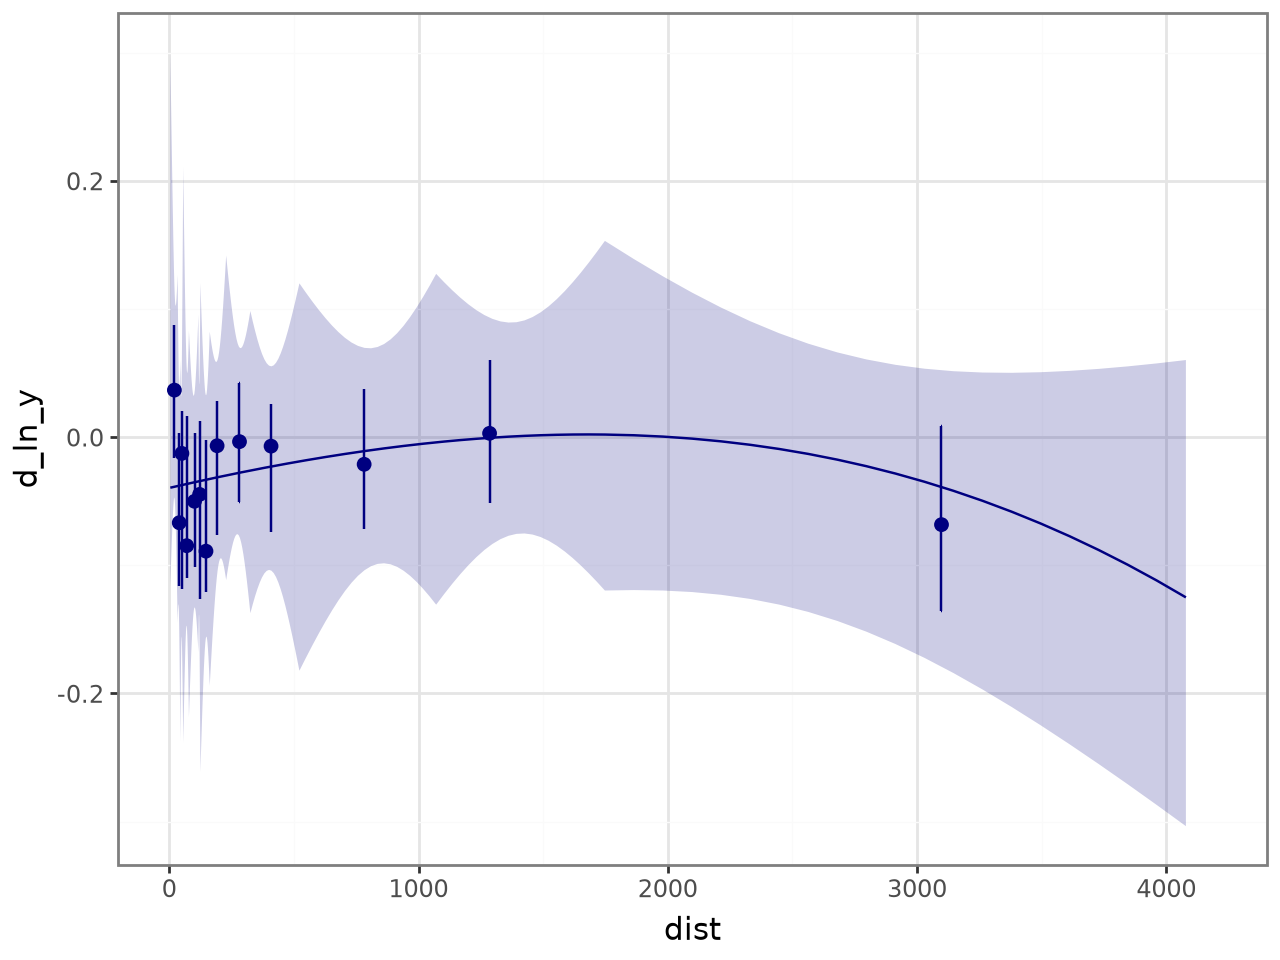

----------------------------------------------------------------------------------------------------
np_dbaa results:
          group  bin_id  left_endpoint  right.endpoint    n
0   Full Sample       1       2.902654       33.728253  360
1   Full Sample       2      33.728253       44.712726  360
2   Full Sample       3      44.712726       56.253220  367
3   Full Sample       4      56.253220       79.102414  352
4   Full Sample       5      79.102414      117.007447  398
5   Full Sample       6     117.007447      125.104837  346
6   Full Sample       7     125.104837      162.579801  339
7   Full Sample       8     162.579801      228.413867  359
8   Full Sample       9     228.413867      325.499957  366
9   Full Sample      10     325.499957      522.237489  350
10  Full Sample      11     522.237489     1070.813182  365
11  Full Sample      12    1070.813182     1747.649344  358
12  Full Sample      13    1747.649344     4194.838591  356


In [30]:
prep = (2010,2014)
ch = dba.copy()

ch = ch.sort_values(['id', 'year']).copy()

boolean = (True, False)

for b in boolean:
    print('-' * 100,
          f'boolean == {b}',
          sep = '\n')
    nparam(ch, y = 'estoque', prep = prep, nbins = None, polyreg = 3, test = b, true_dist = True)

Binstest testa o ajuste dos dados a uma função especificada. No contexto deste caderno, o código acima tem como objetivo selecionar o anel de controle, verificando a relação entre $\Delta_{emprego}$ e a distância das vias que seriam tratadas nos anos seguintes.  

Como o binsreg de $\Delta ln(emprego)$ em função de $ln(dist)$ retornou bins com um comportamento constante, o teste foi realizado para verificar se a função realmente é constante no espaço. Assim, como $H_0$ é que a função segue um comportamente constante ao longo da distância, o p-valor de $0,19$ não permite rejeitá-la. Portanto, não há indícios que $d_C$ não possa ser definido como a distância máxima da base ou podemos optar por defini-la com base na literatura.   

In [56]:
try:
    del prep
    print('prep deleted')
except:
    pass

reg1, agg1 = didnp(base = dba, y_col = 'estoque', d_bins = (0, 2.90, 33.72, 44.71, 56.23, 79.10, 117, 125.10,
                                                      162.57, 228.41, 325.49, 522.23, 1070.81, 1747.64, 4194.83))

print(agg1)

group  bin
2014   2      0.018369
       3      0.006666
       4     -0.008965
       5      0.026852
       6      0.008945
       7      0.011004
       8     -0.024613
       9      0.021129
       10     0.034404
       11     0.013986
       12     0.028777
       13     0.017200
       14     0.024272
2016   2     -0.011202
       3      0.012500
       4      0.001099
       5     -0.130962
       6      0.035801
       7     -0.072702
       8      0.009622
       9     -0.021170
       10    -0.005166
       11     0.007120
       12    -0.019607
       13    -0.099308
       14    -0.111985
2017   2     -0.016550
       3     -0.145436
       4      0.138005
       5      0.290852
       6      0.023819
       7     -0.132933
       8      0.029120
       9     -0.014872
       10     0.130694
       12    -0.603365
       13    -0.030644
2019   2     -0.031604
       3      0.025541
       4     -0.163824
       5      0.025577
       6     -0.021740
       7     -0.088992


# Analysis

### Graph

loading bikes df
bikes loaded


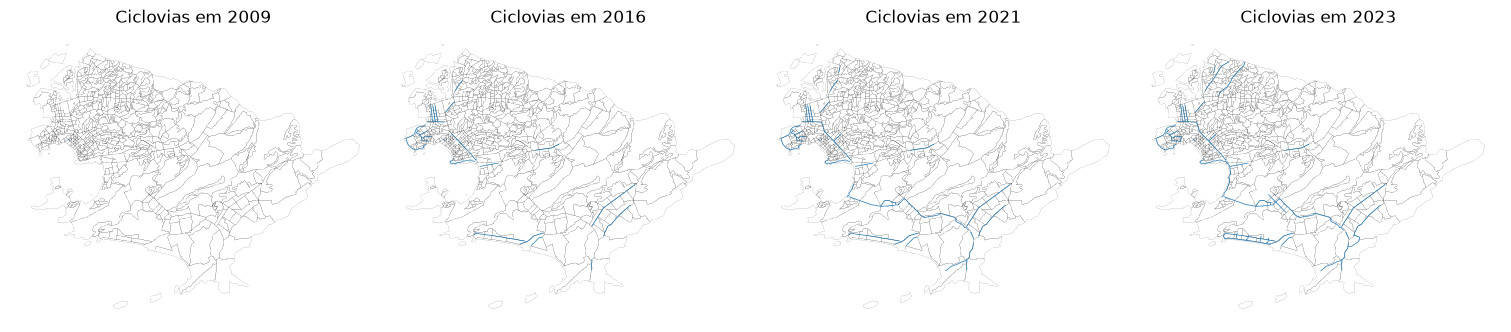

In [30]:
tplot(census)
plt.savefig(r'Resultados/Imagens/Tratamento.png')

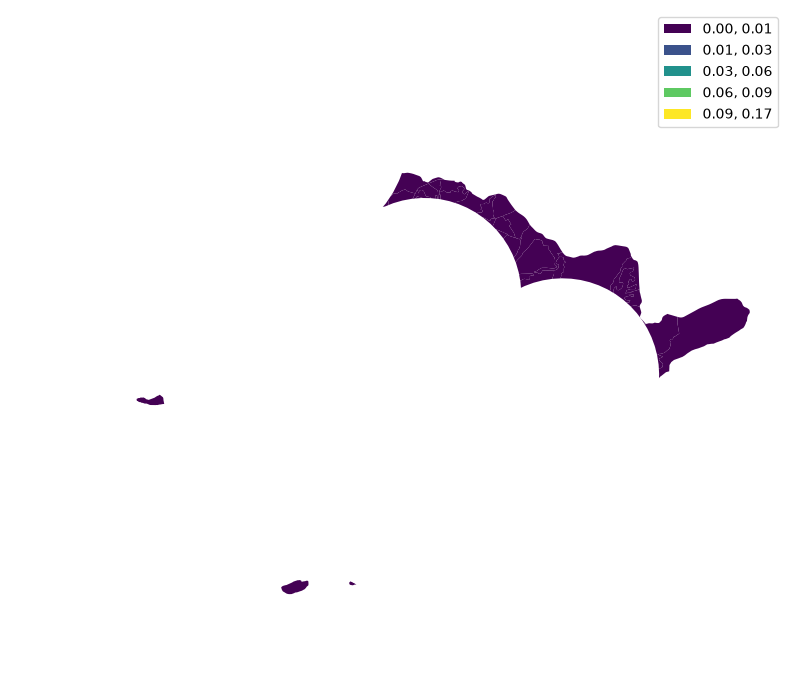

In [92]:
# Firm Avarage Age

fig, ax = plt.subplots(figsize = (10,10))
ax.set_axis_off()

if census.crs != 31982:
        census = census.to_crs(31982)

census[census['year'] == 2022].plot(ax = ax,
        column = 'density',
        scheme = 'FisherJenks',
        k = 5,
        legend = True)


bikes = gpd.read_file(r'Dados/Infraestrutura/Infraestrutura_Cicloviária.shp') 
bikes = bikes.to_crs(census.crs)
bikes['geometry'] = bikes.buffer(3000)
bikes['dt_inaugur'] = bikes['dt_inaugur'].fillna(2050)
bikes['dt_inaugur'] = pd.to_datetime(bikes['dt_inaugur']).dt.year
bikes.loc[(bikes['dt_inaugur'] < 2009), 'dt_inaugur'] = 2050
bikes['dt_inaugur'] = bikes['dt_inaugur'].dropna().astype(str)


bikes.plot(figsize = (10,10),
           ax = ax,
           color = 'white',
           linewidth = 1)

plt.show()


<Axes: >

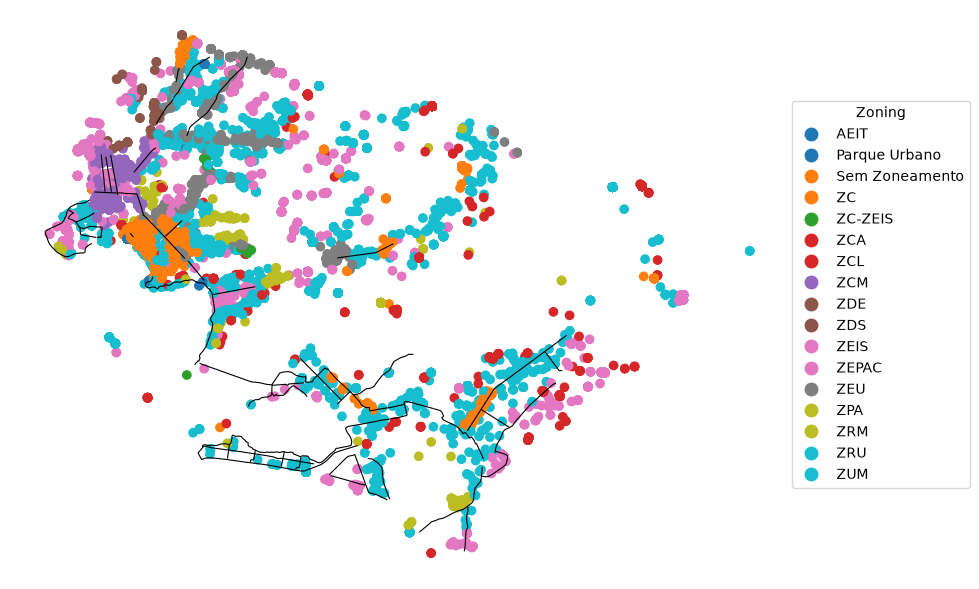

In [32]:
# Zoning

fig, ax = plt.subplots(figsize = (10,10))
ax.set_axis_off()

t[t['year'] == 2022].plot(ax = ax,
        column = 'zone',
        categorical = True,
        legend = True,
        legend_kwds = {'loc':'center left',
                        'bbox_to_anchor':(1,0.5),
                        'title' : "Zoning"})

bikes = gpd.read_file(r'Dados/Infraestrutura/Infraestrutura_Cicloviária.shp') 
bikes = bikes.to_crs(census.crs)
bikes['dt_inaugur'] = bikes['dt_inaugur'].fillna(2050)
bikes['dt_inaugur'] = pd.to_datetime(bikes['dt_inaugur']).dt.year
bikes.loc[(bikes['dt_inaugur'] < 2009), 'dt_inaugur'] = 2050
bikes['dt_inaugur'] = bikes['dt_inaugur'].dropna().astype(str)

bikes.plot(figsize = (10,10),
           ax = ax,
           color = 'black',
           linewidth = .8)


<Axes: >

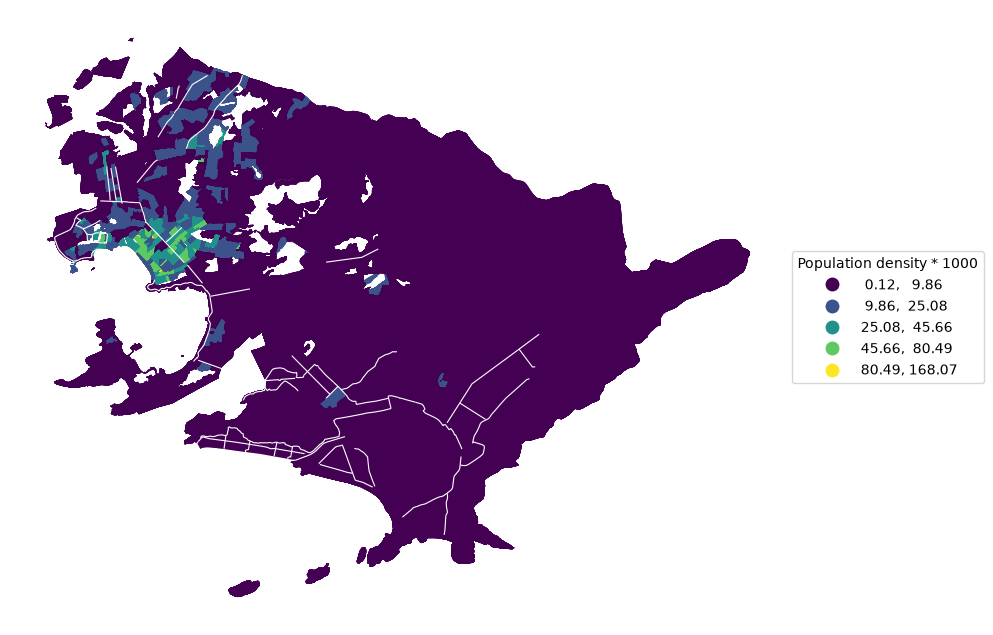

In [33]:
# Population Density

fig, ax = plt.subplots(figsize = (10,10))
ax.set_axis_off()

t_2022 = to[to['year_x'] == 2022].copy()
t_2022['density1000'] = t_2022['density'] * 1000

t_2022.plot(ax = ax,
       column = 'density1000',
       scheme = 'FisherJenks',
       k = 5,
       legend = True,
       legend_kwds = {'loc':'center left',
                     'bbox_to_anchor':(1,0.5),
                     'title' : "Population density * 1000",
                     'fmt': "{:.2f}"},
       figsize = (10,10))

bikes.plot(figsize = (10,10),
           ax = ax,
           color = 'white',
           linewidth = .8)


<Axes: >

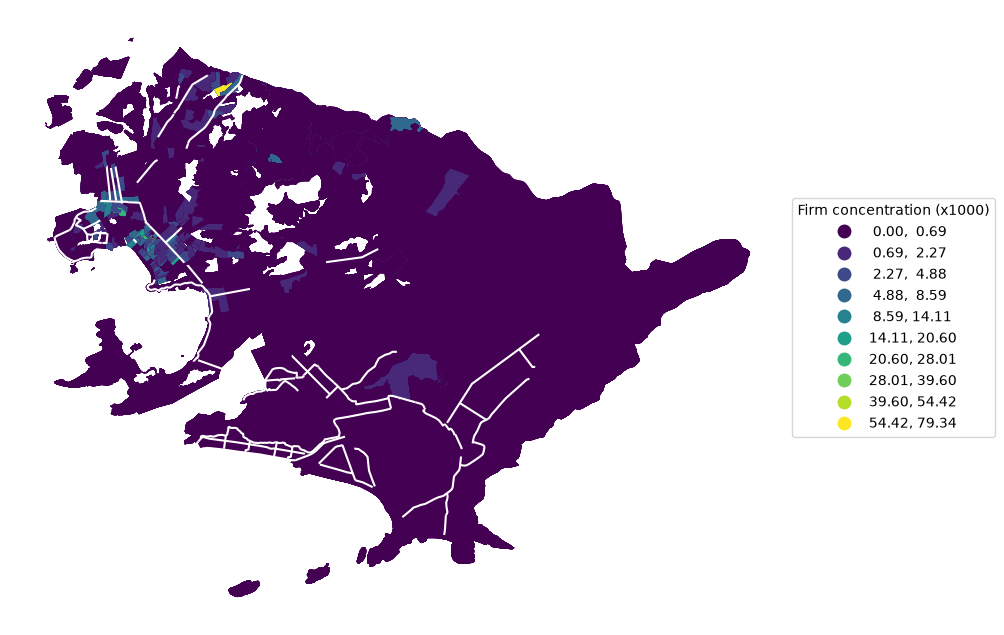

In [34]:
# Firm Density

fig, ax = plt.subplots(figsize=(10,10))
ax.set_axis_off()

t_2022 = to[to['year_x'] == 2022].copy()
t_2022['firm_density_x1000'] = t_2022['firm_density'] * 1000

t_2022.plot(ax=ax,
       column='firm_density_x1000',
       scheme='FisherJenks',
       k=10,
       legend=True,
       legend_kwds={'loc':'center left',
                     'bbox_to_anchor':(1,0.5),
                     'title':"Firm concentration (x1000)",
                     'fmt':"{:.2f}"},
       figsize=(10,10))

bikes.plot(ax=ax, color='white')


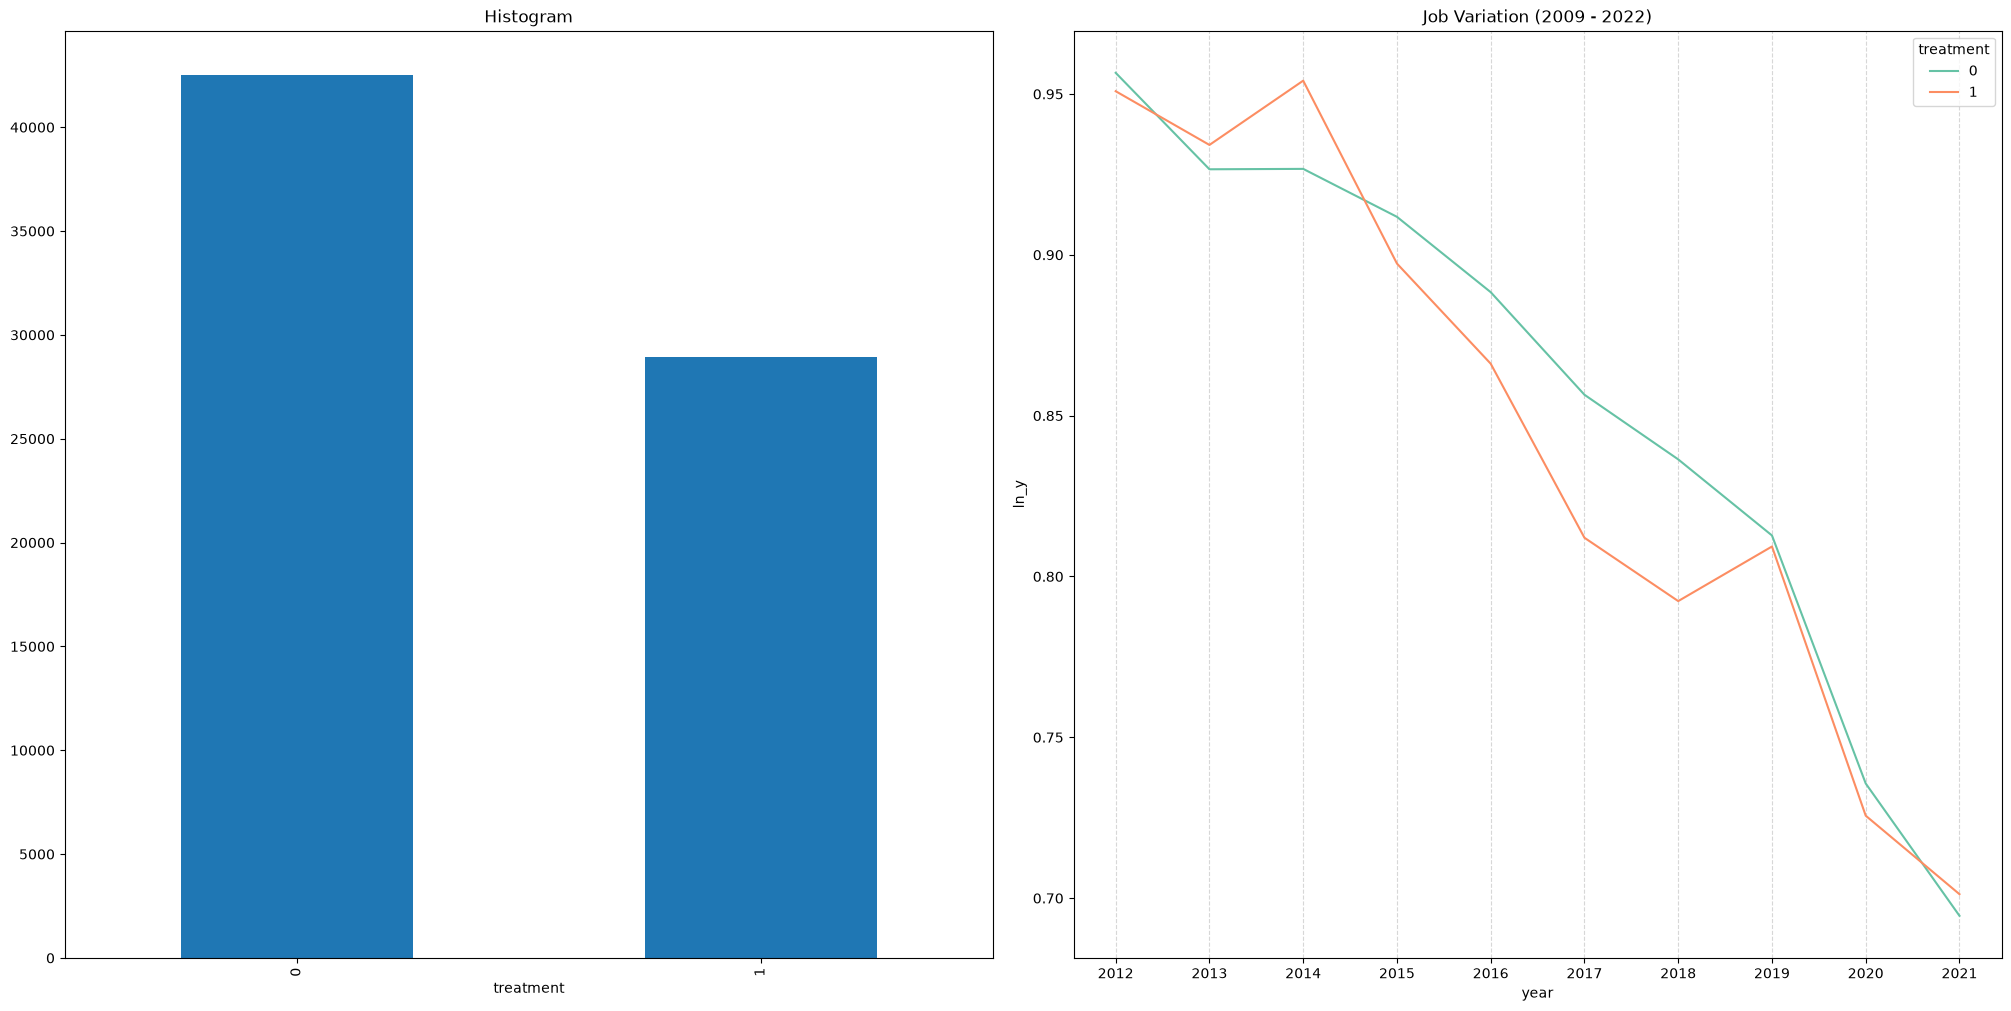

In [72]:
plotu(dbr, y = 'ln_y', name = 'dbr', mean = True)


### Descriptive Analysis

In [91]:
def comparison(base):
      print('------------------------------------------------------------',
            f'Base original: {len(rais_original['id'])}',
            f'Base final: {len(base['id'])}',
            f'Redução de {len(rais_original['id']) - len(base['id'])}, ou seja {1-(len(base['id'])/len(rais_original['id']))}',
            sep = '\n')

comparison(dba)


------------------------------------------------------------
Base original: 379858
Base final: 12517
Redução de 367341, ou seja 0.9670482127531868


In [94]:
sd(dba, name = 'dba')

-----------------------------------------------------------------
-----------------------------------------------------------------
Descrição - dba
Estoque:

group         0      2016     2017      2019      2020      2021     global
count  3656.000  3824.000  219.000  2088.000  1006.000  1724.000  12517.000
mean      4.730    17.994    7.205     3.024    20.759     5.346      9.914
std      20.221   275.610   25.590     7.964   120.298    40.676    157.422
min       0.000     0.000    0.000     0.000     0.000     0.000      0.000
25%       0.000     0.000    0.000     0.000     0.000     0.000      0.000
50%       0.000     0.000    0.000     1.000     0.000     0.000      0.000
75%       3.000     4.000    4.000     3.000     5.000     1.250      3.000
max     503.000  6533.000  163.000   172.000  1401.000   708.000   6533.000
-----------------------------------------------------
Idade:

group         0      2016     2017      2019      2020      2021     global
count  3656.000  382

# Grid
In this section a hex grid is created to help the regression capture heterogenity in the vacinity of treatment

## Data cleaning

### Create hex

In [36]:
try:
    hex = gpd.read_file(r'Dados/Grids_Niteroi_100m.gpkg')
    print("hex loaded")
except Exception as e:
    print(f"Error - hex: {e}")

hex = hex.to_crs(31983)
census = census.to_crs(31983)
print('crs adjusted')

hex = hex[['id','geometry']]
print(f'hex reduced to this keys: {hex.keys()}')

try:
    hex['area'] = hex.geometry.area
    print('hex area created')
except Exception as e:
    print(f'Error - area: {e}')

try:
    intersec = gpd.overlay(
        hex[['id', 'area', 'geometry']],
        census[['year', 'density', 'geometry']], 
        how='intersection')
    print('intersec created')
except Exception as e:
    print(f'Error - intersec: {e}')

try:
    intersec['intersec'] = intersec.geometry.area
    intersec['dens_area'] = intersec['density'] * intersec['intersec']
    print('intersection area and density added to intersec')
except Exception as e:
    print(f'Error - intersec: {e}')

try:
    agg = intersec.groupby(['id', 'year']).agg(
        soma_dens_area=('dens_area', 'sum'),
        sum_area_intersec=('intersec', 'sum')
    ).reset_index()
    print('agg created from intersec')
except Exception as e:
    print(f'Error - agg: {e}')

try:
    agg['density_m'] = agg['soma_dens_area'] / agg['sum_area_intersec']
    print('density_m added to agg')
except Exception as e:
    print(f'Error - agg: {e}')

try:
    hex = hex.merge(
        agg[['id', 'density_m', 'year']],
        on='id',
        how='left')
    print('merge sucessful!')
except Exception as e:
    print(f'Error - merge: {e}')

hex['id'] = hex['id'].astype(str)
print('hex: id column changed to string')

save(hex, "hex")

hex loaded
crs adjusted
hex reduced to this keys: Index(['id', 'geometry'], dtype='str')
hex area created
intersec created
intersection area and density added to intersec
agg created from intersec
density_m added to agg
merge sucessful!
hex: id column changed to string
Saving hex...done!


### Merge - hex + db

In [37]:
db, db_47, db_56, db_47_56 = (merge(d) for d in (DB_r, DB_47, DB_56, DB_47_56))


----------------------------------------------------------------------------------------------------
----------------------------------------------------------------------------------------------------
merging base and hex...done!
defining geometry...done!
filling age and y...done!
grouping base...done!
Sample has 221886 observations
Of that, 0 are null
----------------------------------------------------------------------------------------------------
----------------------------------------------------------------------------------------------------
merging base and hex...done!
defining geometry...done!
filling age and y...done!
grouping base...done!
Sample has 221886 observations
Of that, 0 are null
----------------------------------------------------------------------------------------------------
----------------------------------------------------------------------------------------------------
merging base and hex...done!
defining geometry...done!
filling age and y...done!
group

### Merge - db_a + bikes

In [38]:
names = {'db_hex': db, 'db_47_hex': db_47, 'db_56_hex': db_56, 'db_47_56_hex': db_47_56}

db, db_47, db_56, db_47_56 = (bike(d, name) for name, d in names.items())

names = {'db_hex': db, 'db_47_hex': db_47, 'db_56_hex': db_56, 'db_47_56_hex': db_47_56}


----------------------------------------------------------------------------------------------------
bikes loaded
date format changed
period is: <IntegerArray>
[2014, 2009, 2016, 1899, 2017, 2012, 2019, 2020, 2021, 2022, <NA>, 2023]
Length: 12, dtype: Int64
group changed - 2050
group changed - null
unique dates:
<IntegerArray>
[2014, 2009, 2016, 2050, 2017, 2012, 2019, 2020, 2021, 2022, 2023]
Length: 11, dtype: Int64
sjoin completed
Saving db_hex...done!
----------------------------------------------------------------------------------------------------
----------------------------------------------------------------------------------------------------
bikes loaded
date format changed
period is: <IntegerArray>
[2014, 2009, 2016, 1899, 2017, 2012, 2019, 2020, 2021, 2022, <NA>, 2023]
Length: 12, dtype: Int64
group changed - 2050
group changed - null
unique dates:
<IntegerArray>
[2014, 2009, 2016, 2050, 2017, 2012, 2019, 2020, 2021, 2022, 2023]
Length: 11, dtype: Int64
sjoin completed
Sav

In [39]:
# Define alternative df for regressions

dba, dba_47, dba_56, dba_47_56 = (d.copy() for d in (db, db_47, db_56, db_47_56)) # Non-parametric


### Define treatment

In [40]:
db, db_47, db_56, db_47_56 = (dista(d, dist = 3, b_year = 2010, c_year = 2021, e_year = 2021, og = True) for d in (db, db_47, db_56, db_47_56))

names = {'db_hex': db, 'db_47_hex': db_47, 'db_56_hex': db_56, 'db_47_56_hex': db_47_56}

for name, d in names.items():
    save(d, name)

----------------------------------------------------------------------------------------------------
initializing treatment selection...
distance set to: 3 meters
old columns dropped
dt_inaugur renamed to group
----------------------------------------------------------------------------------------------------
result sample:
       year     id    y                                           geometry  \
15850  2010  10000  2.0  POLYGON ((696173.113 7464158.032, 696201.981 7...   
15851  2010  10001  0.0  POLYGON ((696173.113 7464058.032, 696201.981 7...   
15852  2010  10002  0.0  POLYGON ((696173.113 7463958.032, 696201.981 7...   
15853  2010  10003  0.0  POLYGON ((696173.113 7463858.032, 696201.981 7...   
15854  2010  10004  0.0  POLYGON ((696173.113 7463758.032, 696201.981 7...   

       count zone tx_tipo_left  density_m         area   age  fdensity  group  \
15850      1  ZUM     Ciclovia   0.000051  8660.254038   3.0  0.000115      0   
15851      0  NaN          NaN   0.000047 

## [Alternative Approach - Non-Parametric]

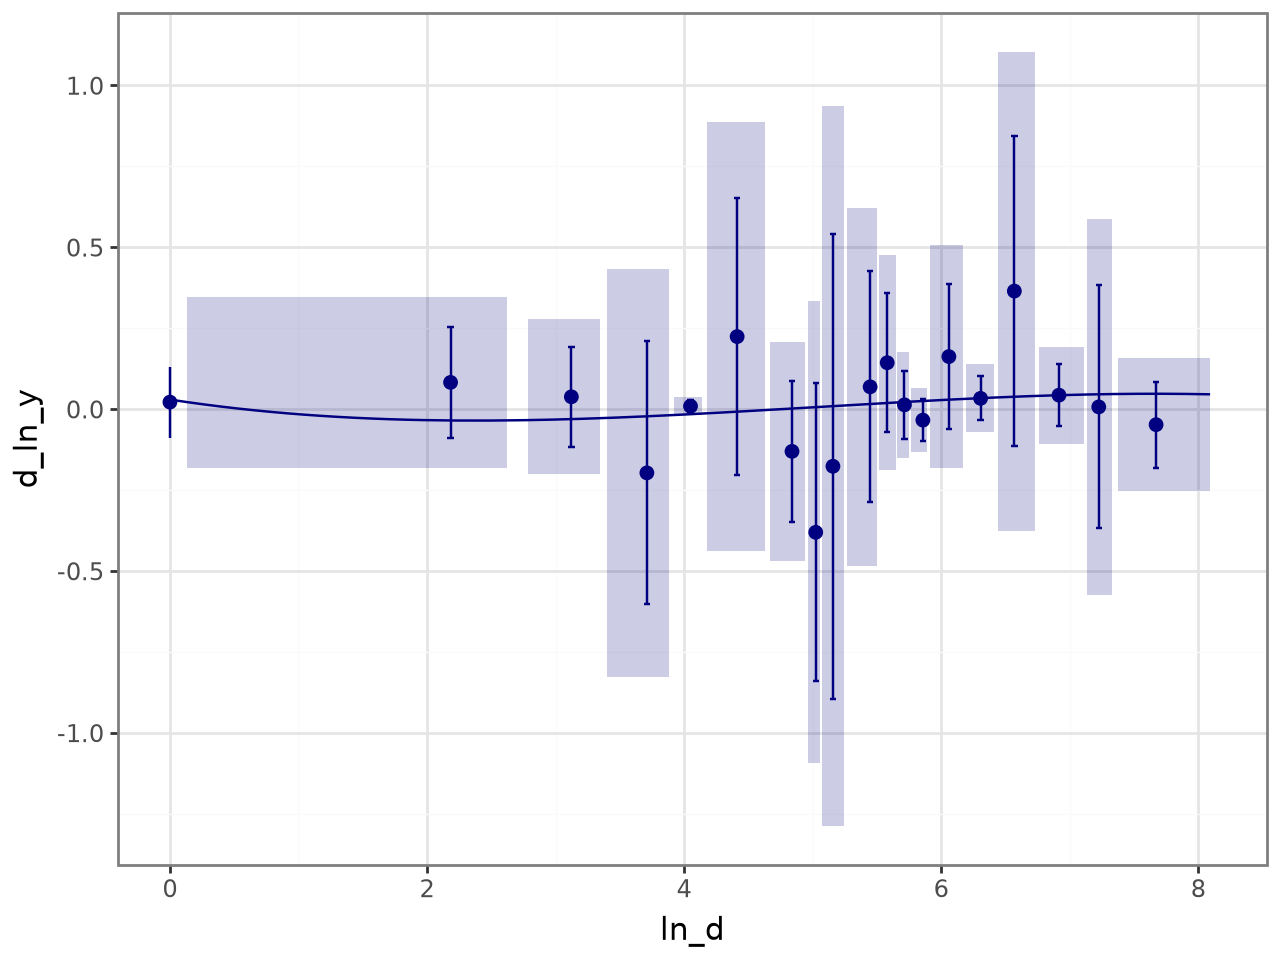

----------------------------------------------------------------------------------------------------
dba results:
          group  bin_id  left_endpoint  right.endpoint   n
0   Full Sample       1       0.000000        0.000000  22
1   Full Sample       2       0.000000        2.754996  10
2   Full Sample       3       2.754996        3.378308  11
3   Full Sample       4       3.378308        3.907851  10
4   Full Sample       5       3.907851        4.154139  11
5   Full Sample       6       4.154139        4.650607  10
6   Full Sample       7       4.650607        4.955056  11
7   Full Sample       8       4.955056        5.064402  10
8   Full Sample       9       5.064402        5.252364  11
9   Full Sample      10       5.252364        5.513260  11
10  Full Sample      11       5.513260        5.652499  10
11  Full Sample      12       5.652499        5.755679  11
12  Full Sample      13       5.755679        5.898264  10
13  Full Sample      14       5.898264        6.184805  11
1

In [41]:
nparam(dba, prep = (2013,2014), name = 'dba')


In [42]:
print(np.exp(3.907851))

49.79183426481914


In [43]:
dba = dista(base = dba, dist = 50)
save(dba,'dba_np')

----------------------------------------------------------------------------------------------------
initializing treatment selection...
distance set to: 50 meters
old columns dropped
dt_inaugur renamed to group
----------------------------------------------------------------------------------------------------
result sample:
       year     id    y                                           geometry  \
47548  2012  10000  0.0  POLYGON ((696173.113 7464158.032, 696201.981 7...   
47549  2012  10001  0.0  POLYGON ((696173.113 7464058.032, 696201.981 7...   
47550  2012  10002  0.0  POLYGON ((696173.113 7463958.032, 696201.981 7...   
47551  2012  10003  0.0  POLYGON ((696173.113 7463858.032, 696201.981 7...   
47552  2012  10004  0.0  POLYGON ((696173.113 7463758.032, 696201.981 7...   

       count zone tx_tipo_left  density_m         area  age  fdensity  group  \
47548      0  NaN          NaN   0.000821  8660.254038  0.0       0.0      0   
47549      0  NaN          NaN   0.000763  

In [44]:
print(dba['treatment'].unique())

[0 1]


In [45]:
dbaa = clean(base = dba, y = 'y', density = 'density_m')
save(dba, 'dba_np')

----------------------------------------------------------------------------------------------------
starting to clean...
base has :99968 units
Base went from 99968 to 99968 after cleaning problematic ids. this represents a reduction of 0 in the sample
0 units droped due to not having group date
0 units dropped due to duplucity
----------------------------------------------------------------------------------------------------
Saving dba_np...done!


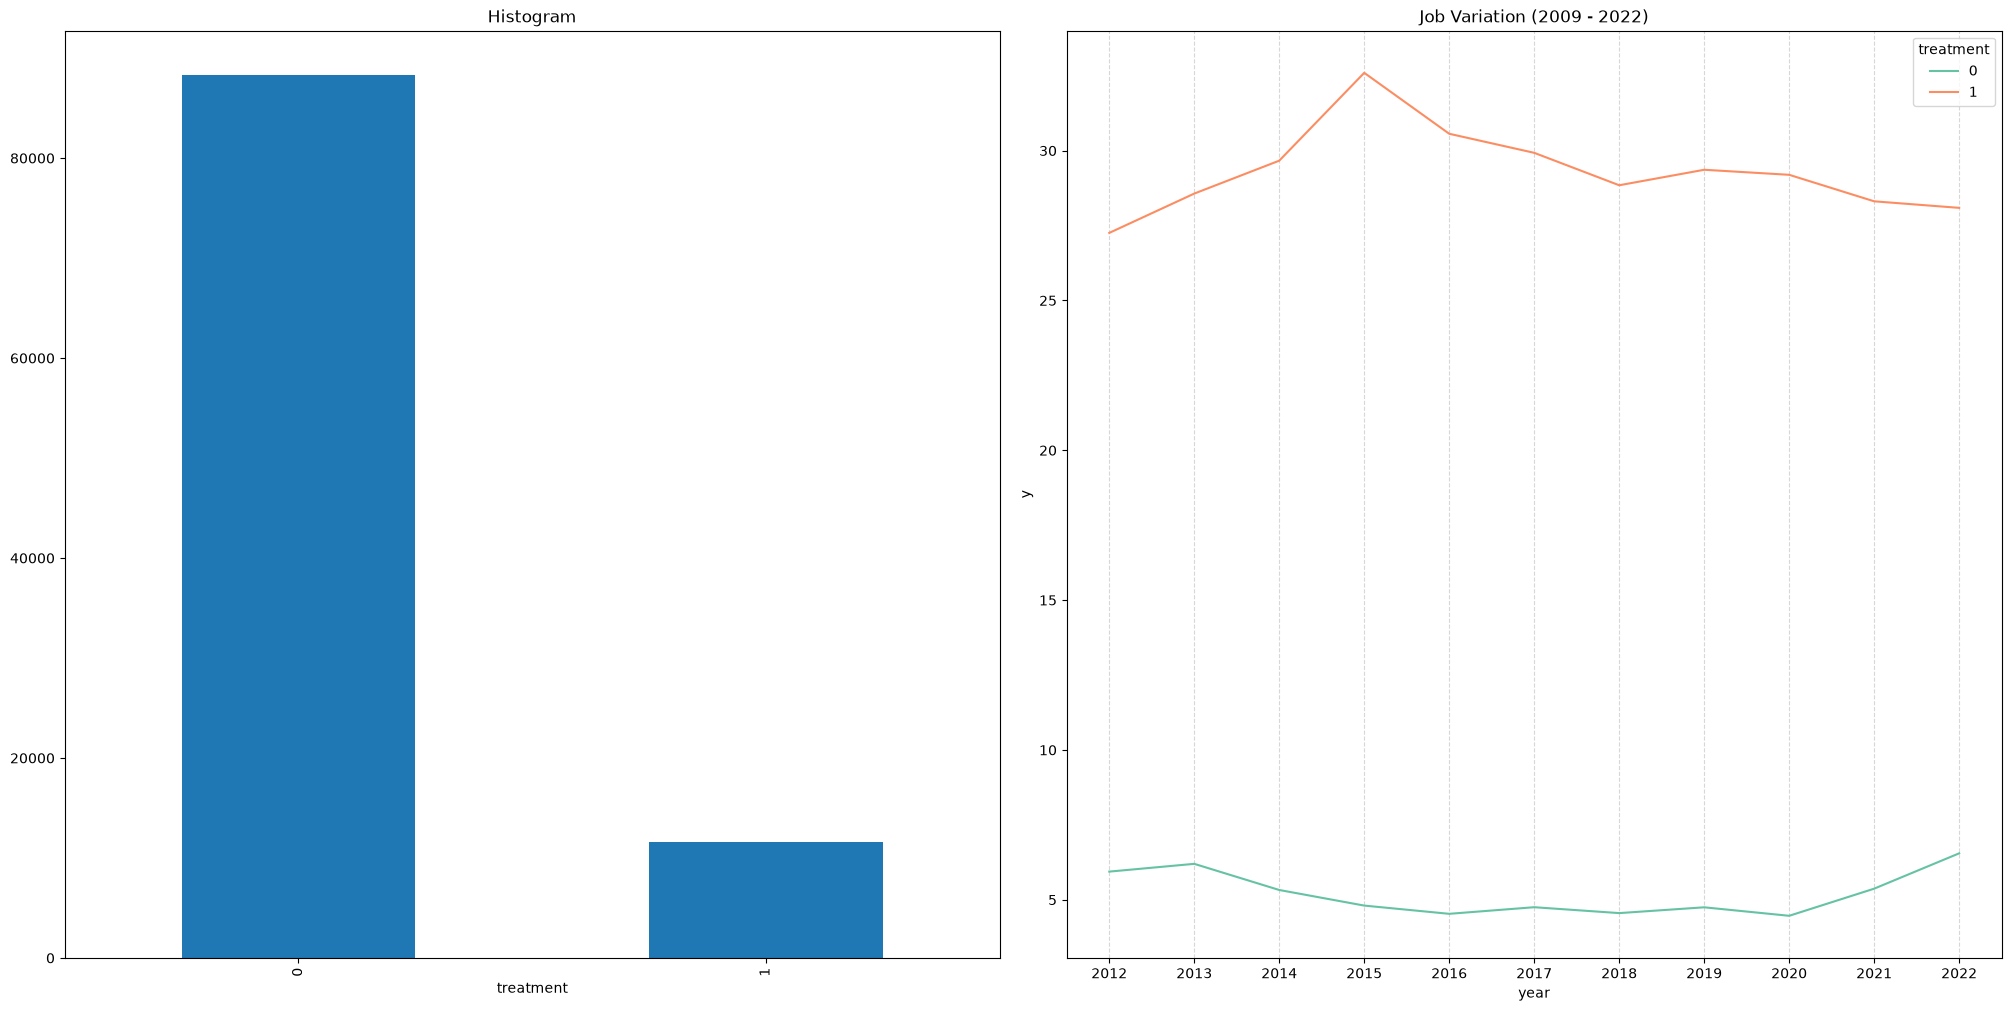

In [46]:
plotu(dba, name = 'dba', mean = True)

## Analysis

### Graphs

In [47]:
def fdensify(base, title = None):
    base['fdensity_10000'] = (base['fdensity'] * 10000)
    base.loc[(base['fdensity_10000'] < 0.09), 'fdensity_10000'] = 0

    fig, ax = plt.subplots(figsize = (10,10),
                        layout = 'constrained')
    ax.set_axis_off()



    base[base['year'] == 2022].plot(ax = ax,
            column='fdensity_10000',
            scheme='FisherJenks',
            k = 11,
            legend=True)
    ax.set_title(f'Firm Density - {title}')

    plt.savefig(f'Resultados/Imagens/fdensity_{title}')

fdensify(db, 'hex')
fdensify(db_47, 'hexa')
fdensify(db_56, 'hexaa')

In [48]:
tplot(db)

loading bikes df


UnboundLocalError: cannot access local variable 'bikes' where it is not associated with a value

----------------------------------------------------------------------------------------------------
starting to clean...
base has :5964 units
Base went from 5964 to 5964 after cleaning problematic ids. this represents a reduction of 0 in the sample
0 units droped due to not having group date
0 units dropped due to duplucity
----------------------------------------------------------------------------------------------------


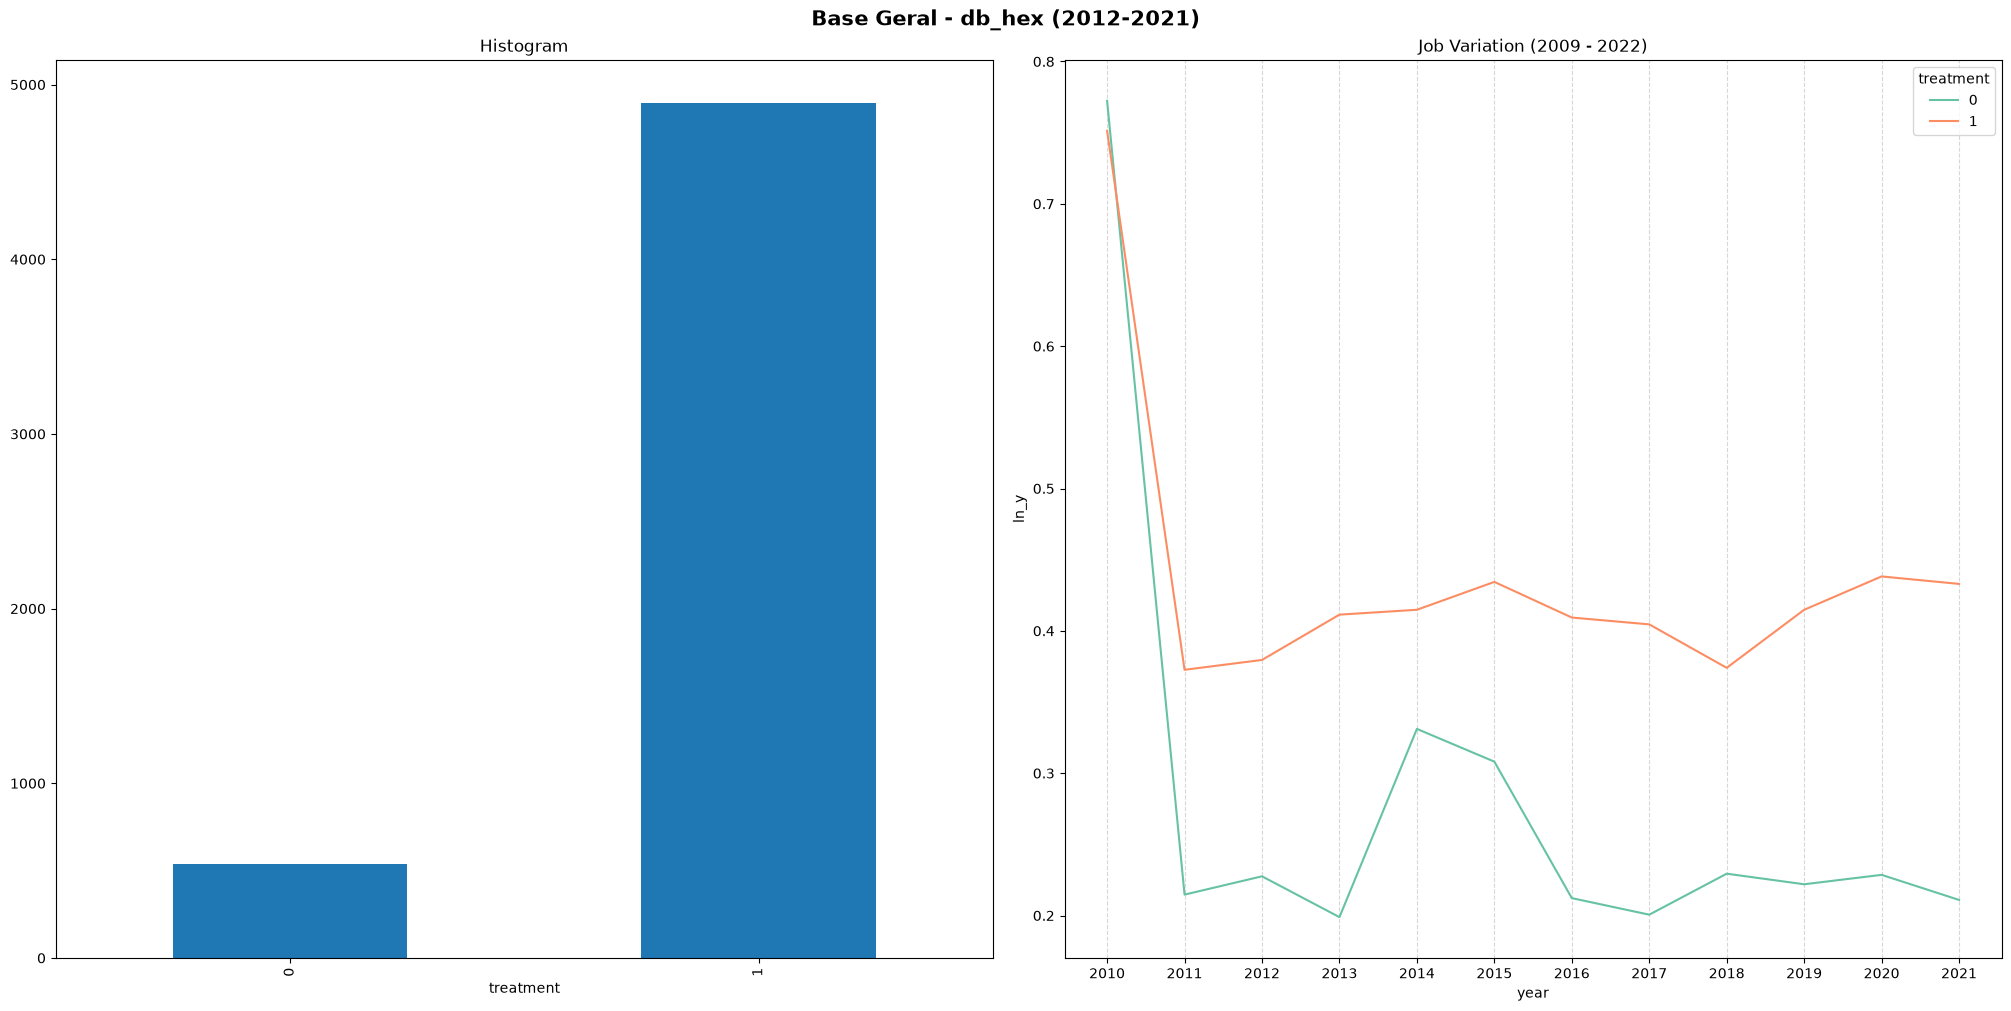

----------------------------------------------------------------------------------------------------
starting to clean...
base has :5964 units
Base went from 5964 to 5964 after cleaning problematic ids. this represents a reduction of 0 in the sample
0 units droped due to not having group date
0 units dropped due to duplucity
----------------------------------------------------------------------------------------------------


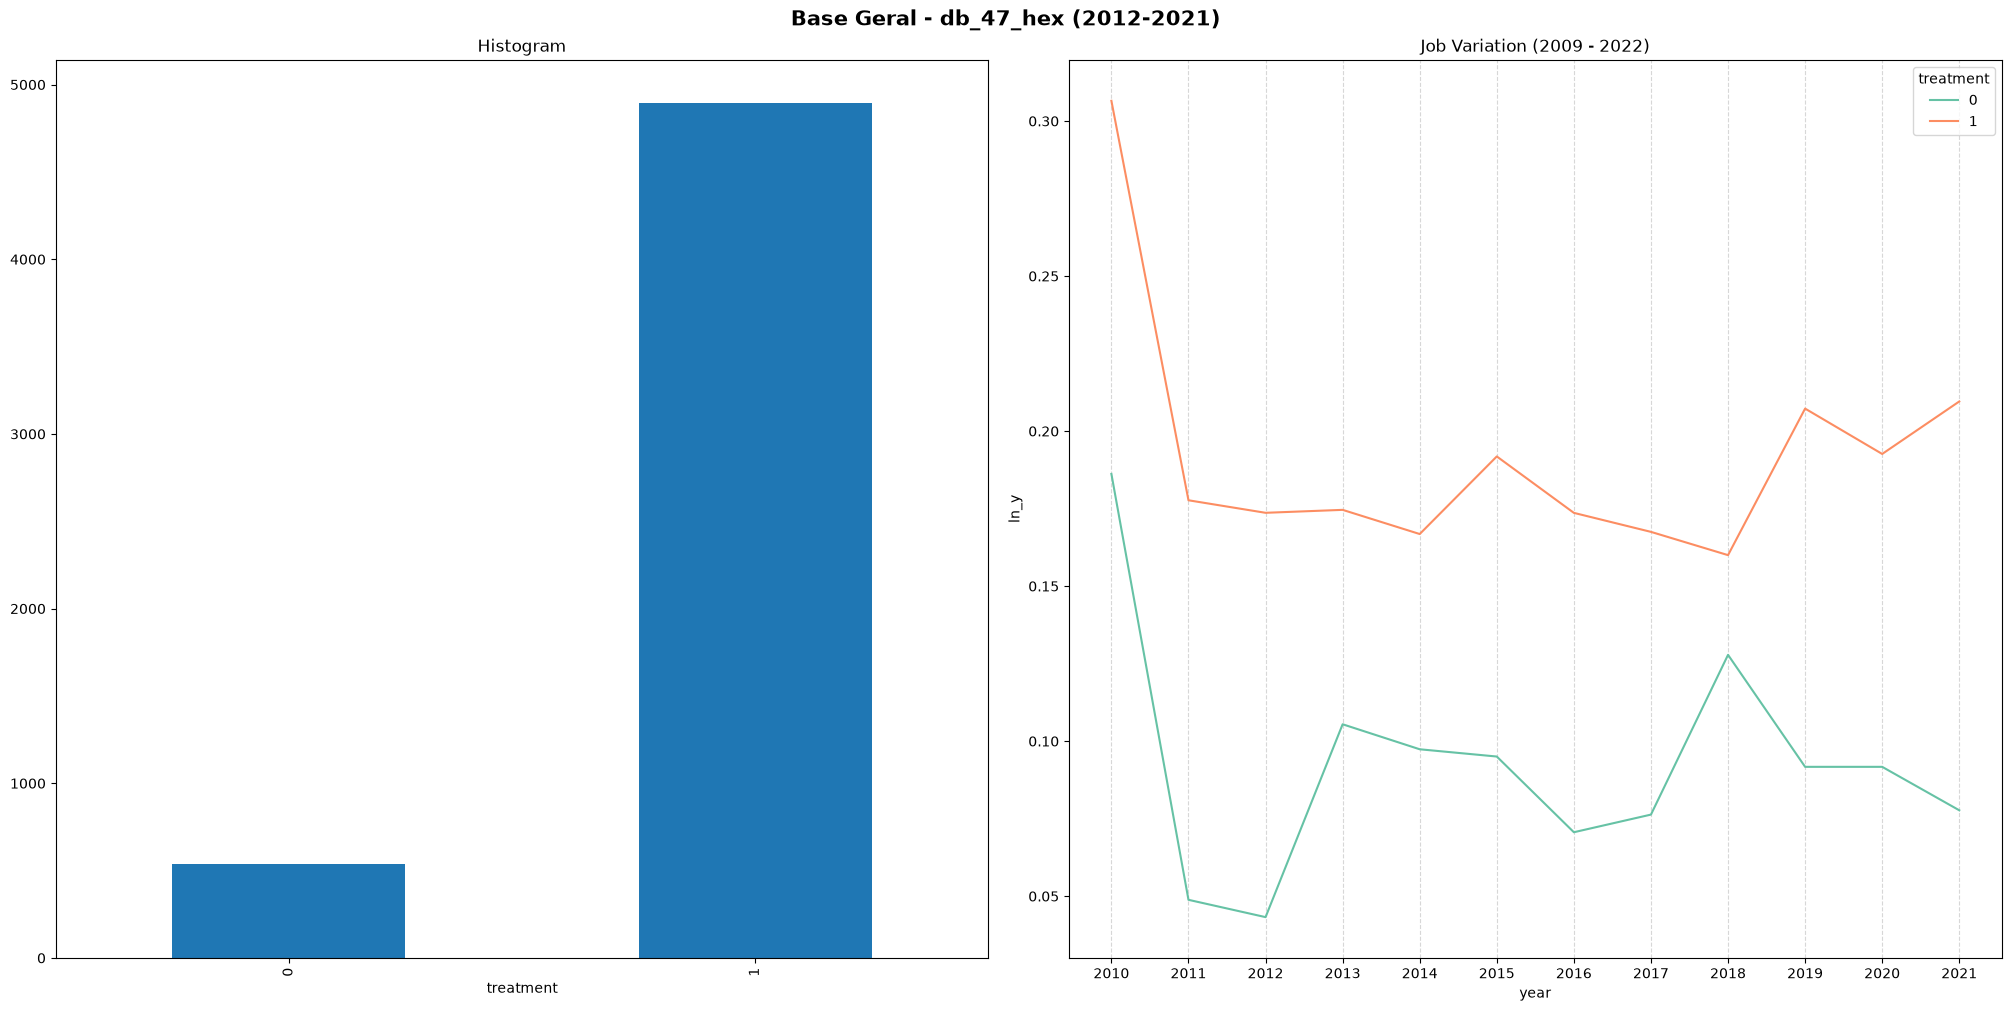

----------------------------------------------------------------------------------------------------
starting to clean...
base has :5964 units
Base went from 5964 to 5964 after cleaning problematic ids. this represents a reduction of 0 in the sample
0 units droped due to not having group date
0 units dropped due to duplucity
----------------------------------------------------------------------------------------------------


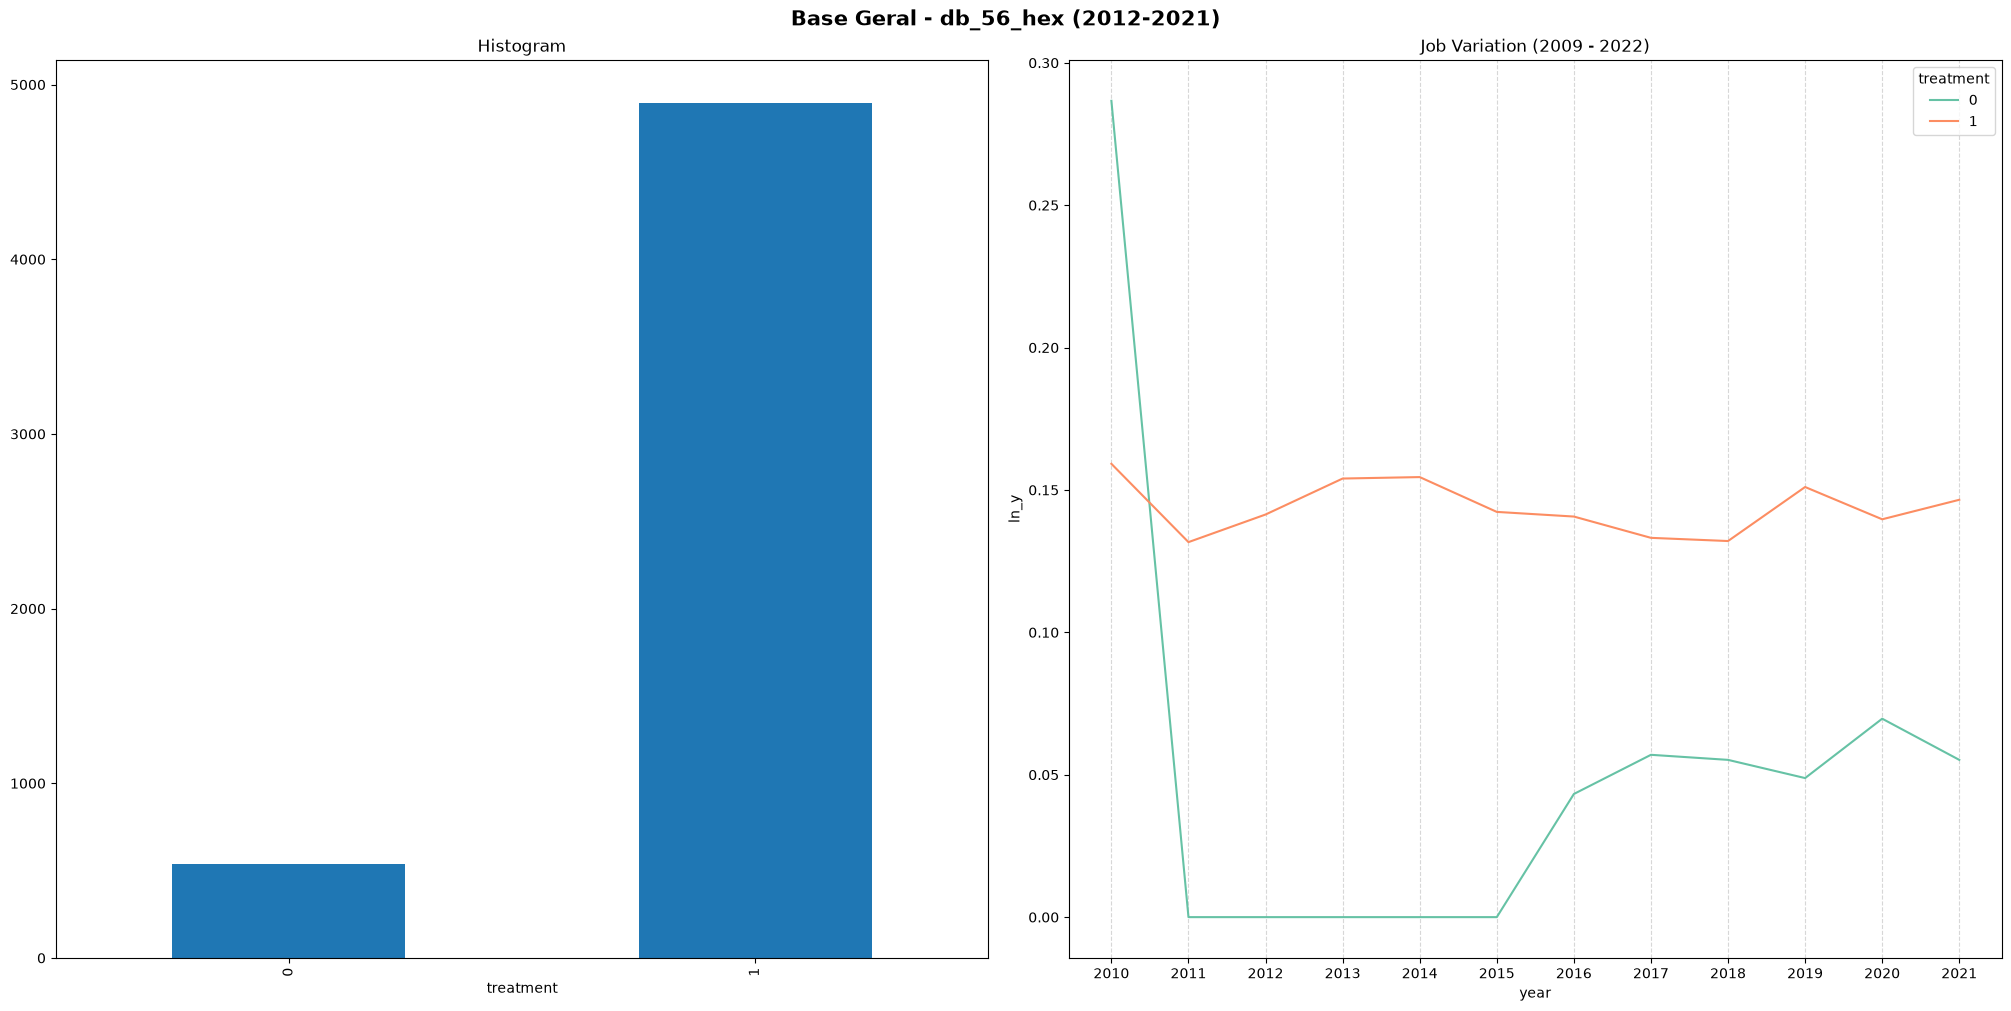

----------------------------------------------------------------------------------------------------
starting to clean...
base has :5964 units
Base went from 5964 to 5964 after cleaning problematic ids. this represents a reduction of 0 in the sample
0 units droped due to not having group date
0 units dropped due to duplucity
----------------------------------------------------------------------------------------------------


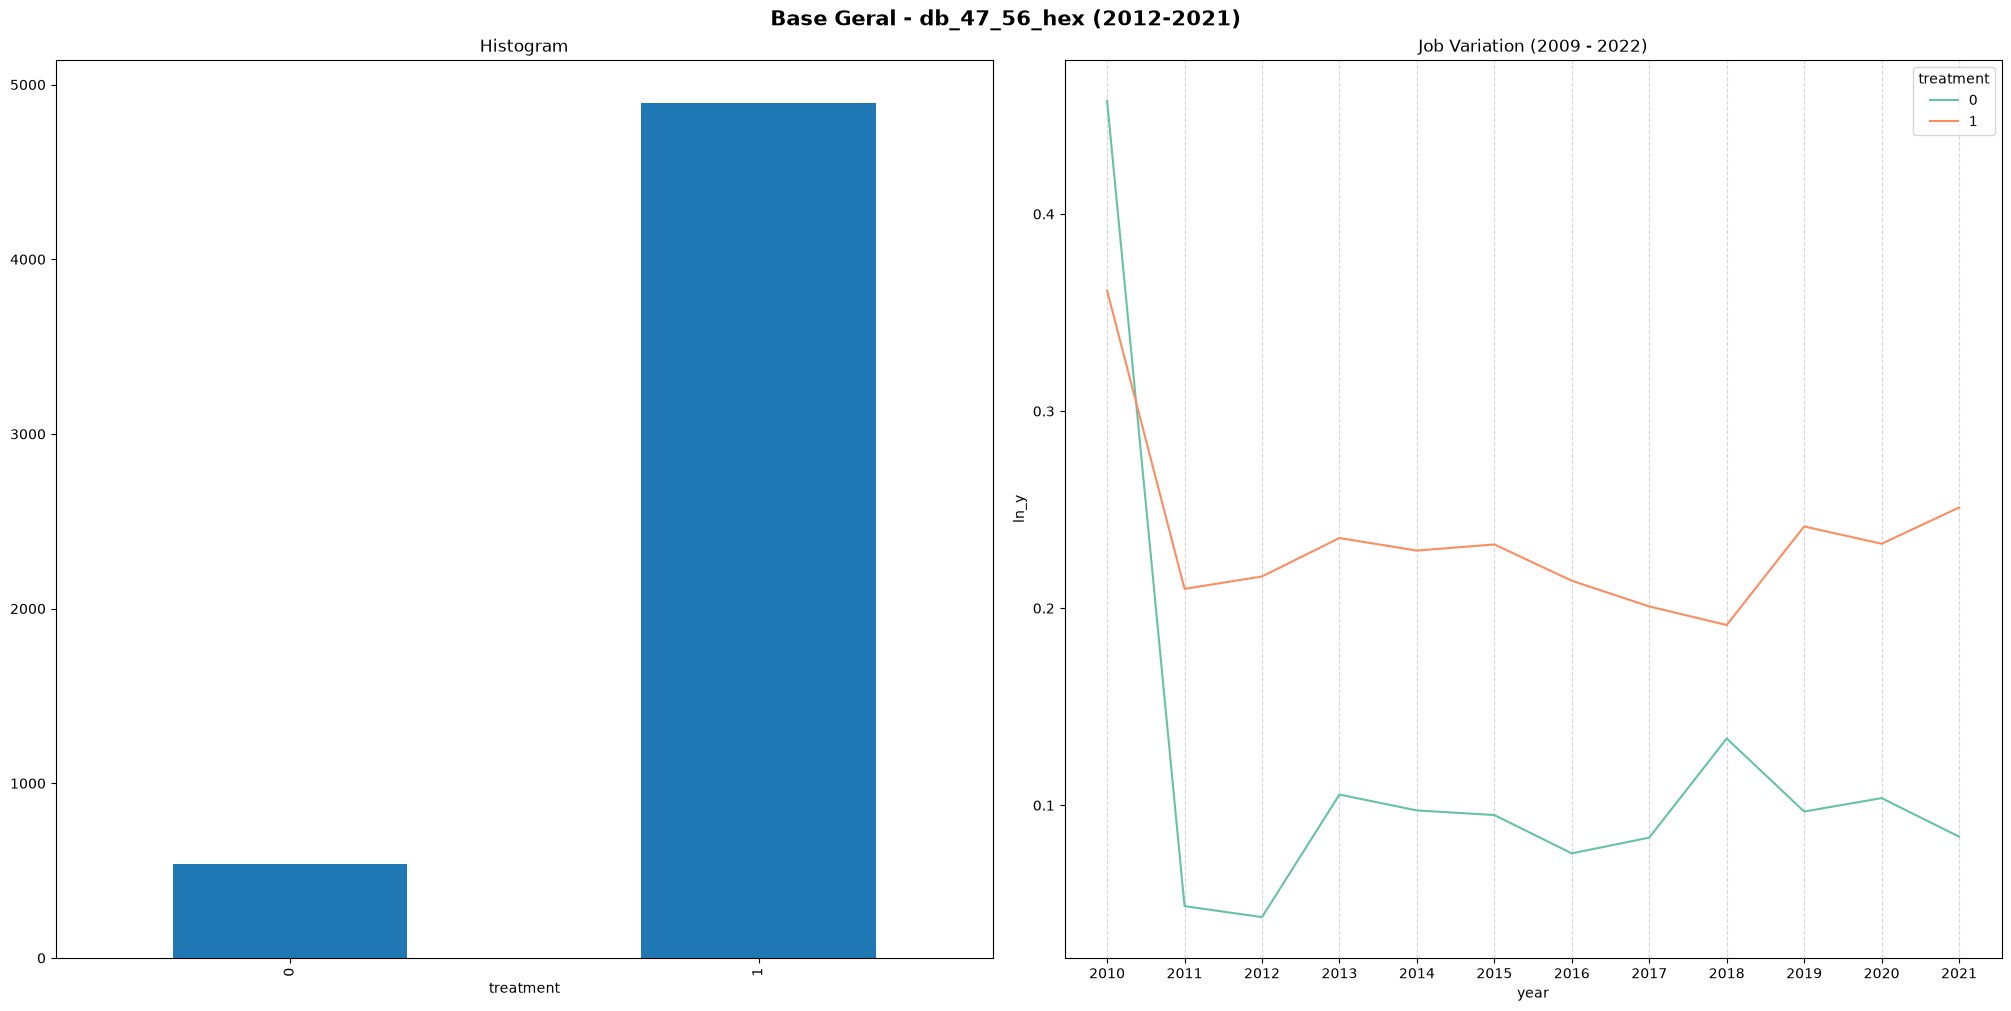

In [ ]:
for name, df in names.items():
    a = clean(df, id = 'id', y = 'y', density = 'density_m')
    plotu(a, y = 'ln_y', name = name, title = f"Base Geral - {name} (2012-2021)", mean = True)


### Descriptive Analysis

In [ ]:
for d in (db, db_47, db_56, db_47_56):
    sd(d, 'base geral')

----------------------------------------------------------------------------------------------------
----------------------------------------------------------------------------------------------------
Descrição - base geral
Estoque:

group  2012      2014     2016      2017      2019      2020     2021  \
count  36.0  2928.000  624.000   480.000  1212.000   132.000  552.000   
mean    0.0    54.095    7.021    14.810    25.437    67.341    3.074   
std     0.0   285.657   44.652   100.219   247.446   359.872   15.421   
min     0.0     0.000    0.000     0.000     0.000     0.000    0.000   
25%     0.0     0.000    0.000     0.000     0.000     0.000    0.000   
50%     0.0     0.000    0.000     0.000     0.000     0.000    0.000   
75%     0.0     0.000    0.000     0.000     0.000     0.000    0.000   
max     0.0  4276.000  640.000  1215.000  3197.000  2380.000  158.000   

group    global  
count  5964.000  
mean     35.429  
std     238.345  
min       0.000  
25%       0.000  

## Export for regression

In [ ]:
try:
    db, db_47, db_56, db_47_56 = (clean(d, id = 'id', y = 'y', density = 'density_m') for d in (db, db_47, db_56, db_47_56))
except:
    pass

names = {'db_hex': db, 'db_47_hex': db_47, 'db_56_hex': db_56, 'db_47_56_hex': db_47_56}

for name, d in names.items():
    save(d, name)

----------------------------------------------------------------------------------------------------
starting to clean...
base has :5964 units
Base went from 5964 to 5964 after cleaning problematic ids. this represents a reduction of 0 in the sample
0 units droped due to not having group date
0 units dropped due to duplucity
----------------------------------------------------------------------------------------------------
----------------------------------------------------------------------------------------------------
starting to clean...
base has :5964 units
Base went from 5964 to 5964 after cleaning problematic ids. this represents a reduction of 0 in the sample
0 units droped due to not having group date
0 units dropped due to duplucity
----------------------------------------------------------------------------------------------------
----------------------------------------------------------------------------------------------------
starting to clean...
base has :5964 units
B